# Real vs Virtual Grasp Classification from Forearm sEMG
## Complete training & evaluation notebook (article classifiers + novel techniques)

Running this notebook **trains every model from scratch** on your recordings and produces all results tables, confusion matrices and figures.

| Step | What happens |
|---|---|
| 1–2 | Read BIOPAC `.acq` files, band-pass 20–450 Hz + 50 Hz notch, detect grasp onsets, cut 1 s windows (0.5 s step) |
| 3 | Feature extraction: article's 20 features/channel + extended + cross-channel features; filter-bank Riemannian covariances |
| 4 | Training engine: per-fold training with progress printout (train/test accuracy, precision, recall, F1) |
| 5 | **Article classifiers** (KNN, Decision Tree, Naive Bayes, Logistic Regression, MLP, SVC) with SMOTE |
| 6 | **Novel techniques**: subject normalisation, LightGBM, Riemannian geometry, hybrid fusion, hierarchical, MiniRocket, 1D-CNN, ensemble |
| 7 | Muscle-configuration analysis (single, dual, triple fusion) |
| 8 | Results tables (article format) — LOSO and 20-fold |
| 9 | Figures: confusion matrices, comparisons, learning curves, per-fold curves, ROC, t-SNE, feature importance … |
| 10 | Train final models on all data, save them, and an inference example |

**Validation:** LOSO (primary, subject-independent) and 20-fold trial-grouped CV (secondary). Scaling, SMOTE and model fitting happen **only inside training folds**. Subject normalisation / Riemannian re-centering use only each subject's own **unlabelled** windows.

**Install once:**
```
pip install bioread imbalanced-learn pyriemann lightgbm aeon torch scikit-learn scipy pandas matplotlib seaborn joblib openpyxl
```

## 0. Configuration

In [1]:
# ===================== EDIT THESE =====================
DATA_DIR    = r"/home/fawadsalamkhan/Downloads/dataset"   # folder containing the .acq files (or a .zip)
OUT_DIR     = r"outputs"     # all results, figures and trained models are written here
CV_SCHEMES  = ["LOSO", "20-fold"]   # remove "20-fold" to halve run time
K_FOLDS     = 20
RUN_MINIROCKET = True        # ~6-15 min per CV scheme on CPU
RUN_CNN        = True        # ~15-30 min per CV scheme on CPU (minutes on a GPU)
DEEP_ON_KFOLD  = False       # also train MiniRocket / CNN under 20-fold (doubles deep-model time)
RUN_MUSCLE_ANALYSIS = True   # single / dual / triple muscle configurations (LOSO)
TUNE_HYPERPARAMS = False     # inner GridSearchCV (grouped by subject) for article classifiers - slow
CNN_EPOCHS  = 30
SEED        = 0
CH_NAMES    = ["FPL", "FDP", "FDS"]   # NOTE: channel 3 is labelled 'EDM' inside the .acq files - verify!
# ======================================================
import os, re, glob, json, zipfile, time, warnings, itertools, copy
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch, decimate
from scipy.stats import skew, kurtosis, wilcoxon
np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); MODEL_DIR = os.path.join(OUT_DIR, "trained_models")
for d in [FIG_DIR, MODEL_DIR]: os.makedirs(d, exist_ok=True)
if DATA_DIR.lower().endswith(".zip"):
    ext = os.path.join(OUT_DIR, "data"); zipfile.ZipFile(DATA_DIR).extractall(ext); DATA_DIR = ext
FS = 2000
CLASS_NAMES = ["Rest", "Real Ball", "Virtual Ball", "Real Remote", "Virtual Remote"]
SHORT = ["Rest", "R-Ball", "V-Ball", "R-Remote", "V-Remote"]
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#9a9994"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})
def savefig(name): plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight"); plt.show()

## 1. Load raw recordings

In [2]:
import bioread
assert os.path.isdir(DATA_DIR), f"DATA_DIR not found: {DATA_DIR}  -> fix the path in the configuration cell"
acq_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.acq"), recursive=True))
print(f"Found {len(acq_files)} .acq files in {DATA_DIR}")
assert acq_files, "No .acq files found - check DATA_DIR (it must contain the BIOPAC .acq files, sub-folders are fine)"
raw = {}
for f in acq_files:
    name = os.path.basename(f).lower()
    s = int(re.match(r"(\d+)", name).group(1)); vr = "vr" in name
    obj = "remote" if ("remote" in name or "rempte" in name) else "ball"
    try:
        a = bioread.read_file(f)
        raw[(s, obj, vr)] = np.stack([c.data for c in a.channels[:3]]).astype(np.float64)
    except Exception as e:
        print(f"SKIPPED (unreadable / empty file): {os.path.basename(f)}")
print(f"{len(raw)} recordings loaded | channel labels stored in files: {[c.name for c in a.channels[:3]]}")

Found 48 .acq files in /home/fawadsalamkhan/Downloads/dataset
SKIPPED (unreadable / empty file): 6 remote.acq
SKIPPED (unreadable / empty file): 6 vr rempte.acq
46 recordings loaded | channel labels stored in files: ['FPL', 'FDP', 'EDM']


## 2. Pre-processing, onset detection and windowing

In [3]:
sos = butter(4, [20, 450], "bandpass", fs=FS, output="sos"); bn, an = iirnotch(50, 30, FS)
CLS = {("ball", False): 1, ("ball", True): 2, ("remote", False): 3, ("remote", True): 4}
W = 2000                                   # 1 s window; 0.5 s step
Xw, y, subj, trial, filt, onsets_all, tid = [], [], [], [], {}, {}, 0
for key in sorted(raw):
    s, obj, vr = key
    x = filtfilt(bn, an, sosfiltfilt(sos, raw[key], axis=1), axis=1); filt[key] = x
    env = np.sqrt(np.convolve((x**2).sum(0), np.ones(400)/400, "same"))
    on = env > np.sqrt(np.percentile(env, 20) * np.percentile(env, 80)); ons = []
    for k in range(6):                     # nominal onsets 5,15,...,55 s refined from the envelope
        nom = (5 + 10*k) * FS; a0, b0 = max(nom - FS, 0), min(nom + FS, len(on) - 1)
        idx = np.where(on[a0:b0] & ~np.r_[False, on[a0:b0-1]])[0]
        onset = a0 + idx[0] if len(idx) else nom; ons.append(onset)
        for w in range(7):                 # grasp windows: onset+0.5 s ... onset+4.5 s
            st = onset + 1000 + w*1000
            if st + W <= x.shape[1]:
                Xw.append(x[:, st:st+W]); y.append(CLS[(obj, vr)]); subj.append(s); trial.append(tid)
        tid += 1
        for w in range(7):                 # rest windows: onset-4.5 s ... onset-0.5 s
            st = onset - 9000 + w*1000
            if st >= 0:
                Xw.append(x[:, st:st+W]); y.append(0); subj.append(s); trial.append(tid)
        tid += 1
    onsets_all[key] = ons
X = np.stack(Xw).astype(np.float32); y = np.array(y); subj = np.array(subj); trial = np.array(trial)
SUBJ = np.unique(subj)
print("windows:", X.shape, "| per class:", dict(zip(CLASS_NAMES, np.bincount(y).tolist())))

windows: (3864, 3, 2000) | per class: {'Rest': 1932, 'Real Ball': 504, 'Virtual Ball': 504, 'Real Remote': 462, 'Virtual Remote': 462}


### Exploratory figures

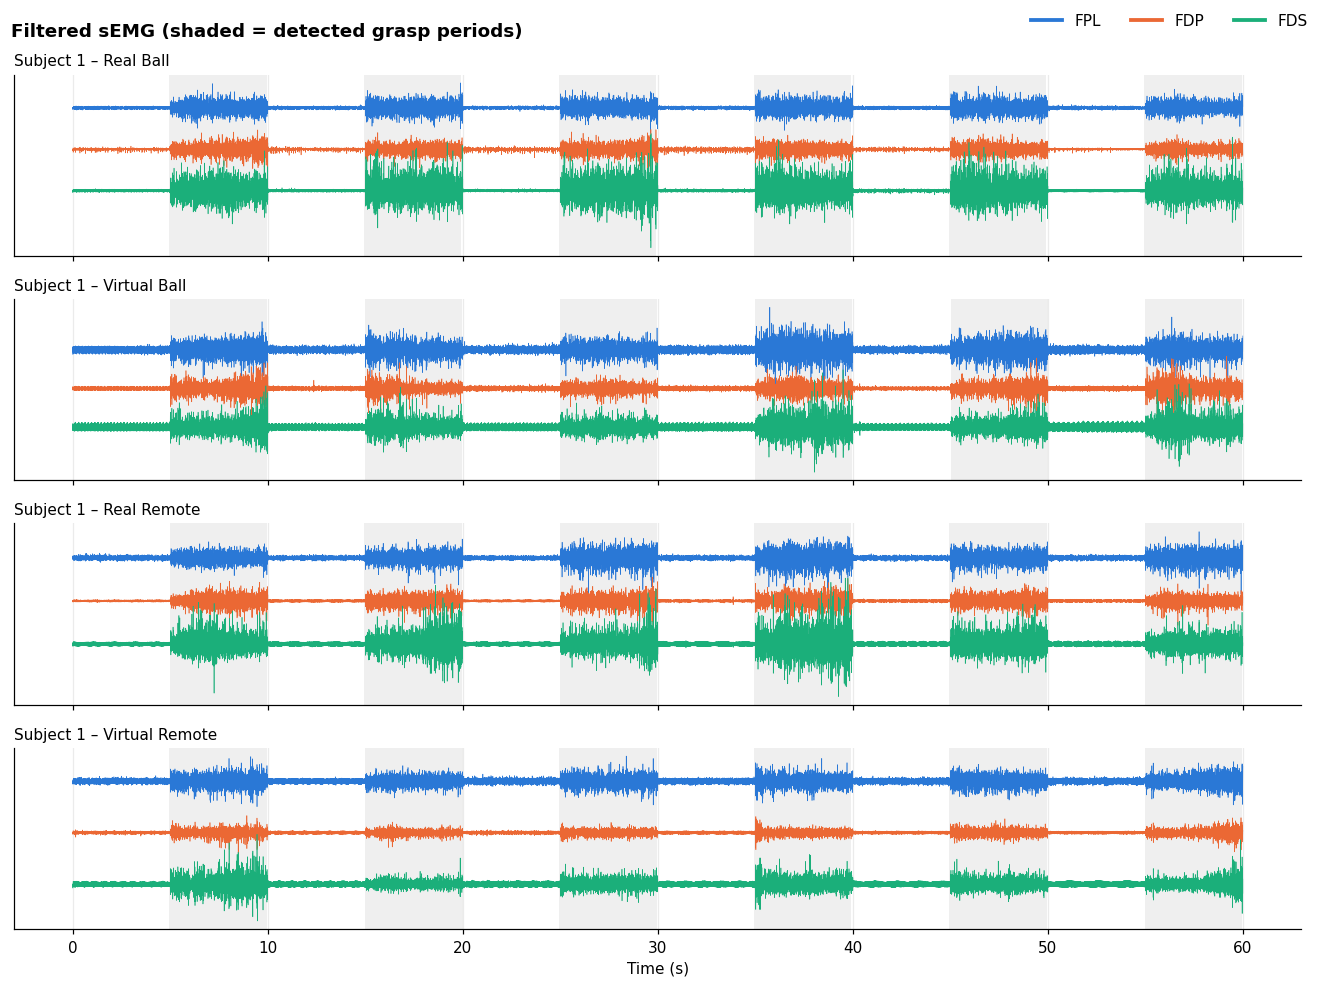

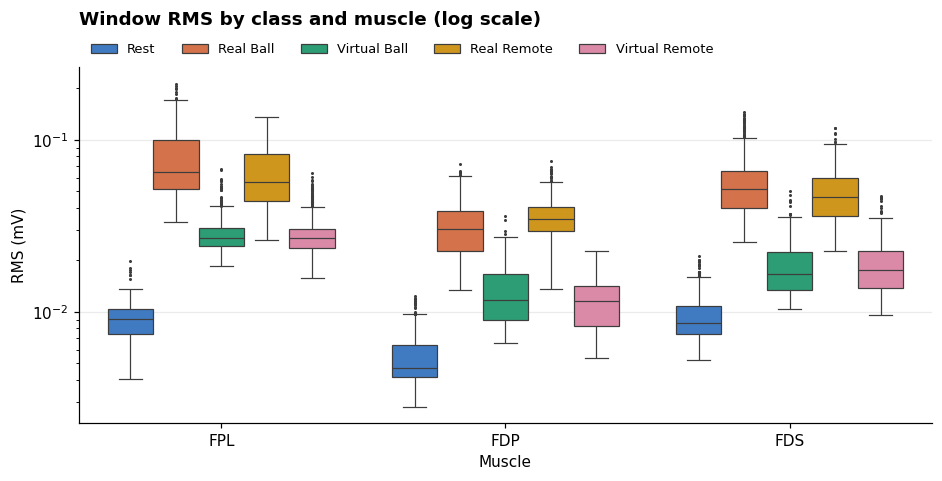

In [4]:
s0 = SUBJ[0]
fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, key in zip(axs, [(s0, "ball", False), (s0, "ball", True), (s0, "remote", False), (s0, "remote", True)]):
    if key not in filt: ax.axis("off"); continue
    x = filt[key]; t = np.arange(x.shape[1]) / FS
    for c in range(3): ax.plot(t[::4], x[c, ::4] - c*0.6*np.abs(x).max(), lw=.4, color=PAL[c], label=CH_NAMES[c])
    for o in onsets_all[key]: ax.axvspan(o/FS, o/FS + 5, color=GREY, alpha=.15, lw=0)
    ax.set_title(f"Subject {s0} – {CLASS_NAMES[CLS[key[1:]]]}", loc="left", fontsize=10); ax.set_yticks([])
h, l = axs[0].get_legend_handles_labels(); lg = fig.legend(h, l, ncol=3, loc="upper right", frameon=False)
for ln in lg.get_lines(): ln.set_linewidth(2.5)
axs[-1].set_xlabel("Time (s)"); fig.suptitle("Filtered sEMG (shaded = detected grasp periods)", x=.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig("fig01_signals")

rms_w = np.sqrt((X.astype(np.float64)**2).mean(-1))
df_rms = pd.DataFrame({"RMS (mV)": rms_w.ravel(), "Muscle": np.tile(CH_NAMES, len(y)), "Class": np.repeat(np.array(CLASS_NAMES)[y], 3)})
plt.figure(figsize=(10, 4.2))
sns.boxplot(data=df_rms, x="Muscle", y="RMS (mV)", hue="Class", hue_order=CLASS_NAMES, palette=PAL[:5], fliersize=1, linewidth=.8)
plt.yscale("log"); plt.title("Window RMS by class and muscle (log scale)", loc="left", fontweight="bold", pad=28)
plt.legend(ncol=5, frameon=False, bbox_to_anchor=(0, 1.0), loc="lower left", fontsize=8.5); savefig("fig02_rms_box")

## 3. Feature extraction

In [5]:
def extract_features(X):
    X = X.astype(np.float64); N, C, T = X.shape
    f, P = welch(X, fs=FS, nperseg=512, axis=-1)
    band = lambda lo, hi: P[..., (f >= lo) & (f < hi)].sum(-1)
    tot = P.sum(-1) + 1e-20; Pn = P / tot[..., None]; cum = np.cumsum(Pn, -1)
    rms = np.sqrt((X**2).mean(-1)); dX = np.diff(X, axis=-1); ddX = np.diff(dX, axis=-1); mnf = (Pn*f).sum(-1)
    paper = {"RMS": rms, "MAV": np.abs(X).mean(-1), "IEMG": np.abs(X).sum(-1),
        "ZC": (np.diff(np.signbit(X).astype(np.int8), axis=-1) != 0).sum(-1), "MEAN": X.mean(-1), "STD": X.std(-1),
        "SKEW": skew(X, axis=-1), "KURT": kurtosis(X, axis=-1), "P2P": X.max(-1) - X.min(-1),
        "RMSD": np.sqrt((dX**2).mean(-1)), "MNF": mnf, "MDF": f[np.argmax(cum >= .5, -1)], "PKF": f[np.argmax(P, -1)],
        "SBW": np.sqrt((Pn*(f - mnf[..., None])**2).sum(-1)), "SENT": -(Pn*np.log(Pn + 1e-20)).sum(-1)/np.log(P.shape[-1]),
        "SFLAT": np.exp(np.log(P + 1e-30).mean(-1))/(P.mean(-1) + 1e-30), "TPOW": tot,
        "BP20_150": band(20, 150), "BP150_500": band(150, 500), "ROLL85": f[np.argmax(cum >= .85, -1)]}
    p = 4; r = np.stack([(X[..., :T-k]*X[..., k:]).mean(-1) for k in range(p+1)], -1)       # AR(4) Yule-Walker
    Rm = np.stack([np.stack([r[..., abs(i-j)] for j in range(p)], -1) for i in range(p)], -2)
    A = np.linalg.solve(Rm + 1e-12*np.eye(p), r[..., 1:, None])[..., 0]
    v0, v1, v2 = X.var(-1), dX.var(-1), ddX.var(-1); mob = np.sqrt(v1/v0)
    ext = {"logRMS": np.log(rms), "WL": np.abs(dX).sum(-1), "SSC": ((dX[..., :-1]*dX[..., 1:]) < 0).sum(-1),
        "WAMP": (np.abs(dX) > .5*X.std(-1, keepdims=True)).sum(-1), "HJ_MOB": mob, "HJ_COMP": np.sqrt(v2/v1)/mob,
        "AR1": A[..., 0], "AR2": A[..., 1], "AR3": A[..., 2], "AR4": A[..., 3], "LD": np.exp(np.log(np.abs(X) + 1e-12).mean(-1)),
        "V3": np.cbrt((X**3).mean(-1)), "BPrel_20_80": band(20, 80)/tot, "BPrel_80_150": band(80, 150)/tot,
        "BPrel_150_250": band(150, 250)/tot, "BPrel_250_450": band(250, 450)/tot, "MNP": P.mean(-1)}
    stack = lambda d: (np.concatenate([np.asarray(v, float).reshape(N, C) for v in d.values()], 1),
                       [f"{k}_{CH_NAMES[c]}" for k in d for c in range(C)])
    Fp, n_p = stack(paper); Fe, n_e = stack(ext)
    lr = np.log(rms); cross, n_x = [], []
    for a in range(C):
        for b in range(a+1, C):
            cross.append(lr[:, a] - lr[:, b]); n_x.append(f"logRMSratio_{CH_NAMES[a]}/{CH_NAMES[b]}")
            xa = X[:, a] - X[:, a].mean(-1, keepdims=True); xb = X[:, b] - X[:, b].mean(-1, keepdims=True)
            cross.append((xa*xb).mean(-1)/(xa.std(-1)*xb.std(-1))); n_x.append(f"corr_{CH_NAMES[a]}-{CH_NAMES[b]}")
    return Fp, n_p, Fe, n_e, np.stack(cross, 1), n_x

F_paper, N_paper, F_ext, N_ext, F_cross, N_cross = extract_features(X)
F_all = np.hstack([F_paper, F_ext, F_cross]); N_all = N_paper + N_ext + N_cross

def logpos(M):
    M = M.copy(); pos = (M > 0).all(0); M[:, pos] = np.log(M[:, pos]); return M
def subject_norm(M):
    """Unsupervised per-subject z-scoring using each subject's own unlabelled windows."""
    M = M.copy()
    for u in SUBJ:
        m = subj == u; M[m] = (M[m] - M[m].mean(0)) / (M[m].std(0) + 1e-9)
    return M
F_hand = subject_norm(logpos(F_paper))            # article features, log + subject-normalised
F_allN = subject_norm(logpos(F_all))              # all features, log + subject-normalised
pd.DataFrame(F_paper, columns=N_paper).assign(label=y, subject=subj).to_csv(os.path.join(OUT_DIR, "features_article.csv"), index=False)
print("article features:", F_paper.shape, "| all features:", F_all.shape)

article features: (3864, 60) | all features: (3864, 117)


### Filter-bank Riemannian covariance features (novel)

In [6]:
from pyriemann.estimation import Covariances
from pyriemann.utils.mean import mean_riemann
from pyriemann.utils.base import invsqrtm, logm
BANDS = [(20, 50), (50, 90), (90, 150), (150, 250), (250, 450)]
COV = np.stack([Covariances("oas").fit_transform(sosfiltfilt(butter(4, b, "bandpass", fs=FS, output="sos"),
                X.astype(np.float64), axis=-1)) for b in BANDS], 1)          # (N, bands, 3, 3)
def riemann_features(Cb):
    """Per-subject re-centering (whiten by the subject's Riemannian mean) + tangent-space mapping."""
    Cb = Cb.copy()
    for u in SUBJ:
        m = subj == u
        for b in range(Cb.shape[1]):
            Wm = invsqrtm(mean_riemann(Cb[m, b])); Cb[m, b] = Wm @ Cb[m, b] @ Wm
    iu = np.triu_indices(Cb.shape[-1]); wts = np.where(iu[0] == iu[1], 1, np.sqrt(2))
    return np.hstack([np.stack([logm(c)[iu]*wts for c in Cb[:, b]]) for b in range(Cb.shape[1])])
F_riem = riemann_features(COV)
F_hyb = np.hstack([F_hand, F_riem])
# raw-signal input for MiniRocket / CNN: 1 kHz, per-subject per-channel amplitude normalisation
Xn = decimate(X.astype(np.float64), 2, axis=-1)
for u in SUBJ:
    m = subj == u; Xn[m] /= np.sqrt((Xn[m]**2).mean((0, 2)))[None, :, None]
Xn = Xn.astype(np.float32)
print("Riemannian features:", F_riem.shape, "| raw input:", Xn.shape)

Riemannian features: (3864, 30) | raw input: (3864, 3, 1000)


## 4. Training engine

In [7]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report, roc_curve, auc)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as imb_pipe

SPLITS = {"LOSO": [(np.where(subj != u)[0], np.where(subj == u)[0], f"S{u}") for u in SUBJ]}
sgk = StratifiedGroupKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)   # windows of one trial never split
SPLITS["20-fold"] = [(tr, te, f"F{i+1}") for i, (tr, te) in enumerate(sgk.split(np.zeros(len(y)), y, groups=trial))]
PROBA, FOLDS, SUMMARY, MODELS_INFO = {}, {}, [], {}
CURRENT = {}                     # gives tuned models access to training groups / monitoring data

def summarise(name, cv, P, fold_df, show=True):
    pred = P.argmax(1); g = y > 0; tp = np.zeros_like(P)
    for t in np.unique(trial): m = trial == t; tp[m] = P[m].mean(0)
    tpred = tp.argmax(1)
    row = {"Model": name, "CV": cv,
           "Train Accuracy": fold_df["train_acc"].mean()*100 if fold_df is not None else np.nan,
           "Test Accuracy": accuracy_score(y, pred)*100,
           "Precision": precision_score(y, pred, average="macro", zero_division=0)*100,
           "Recall": recall_score(y, pred, average="macro")*100, "F1 score": f1_score(y, pred, average="macro")*100,
           "Balanced Acc": balanced_accuracy_score(y, pred)*100, "Grasp-only Acc": accuracy_score(y[g], pred[g])*100,
           "Trial Acc": accuracy_score(y, tpred)*100, "Trial F1": f1_score(y, tpred, average="macro")*100,
           "Fold Acc mean": fold_df["test_acc"].mean()*100 if fold_df is not None else np.nan,
           "Fold Acc SD": fold_df["test_acc"].std()*100 if fold_df is not None else np.nan}
    SUMMARY[:] = [r for r in SUMMARY if not (r["Model"] == name and r["CV"] == cv)] + [row]
    PROBA[(name, cv)] = P
    if show:
        print(f"==> {name} [{cv}]  train {row['Train Accuracy']:.2f} | test {row['Test Accuracy']:.2f} | "
              f"P {row['Precision']:.2f} R {row['Recall']:.2f} F1 {row['F1 score']:.2f} | trial F1 {row['Trial F1']:.2f}\n")
    return row

def train_eval(name, builder, Xf, cv="LOSO", verbose=True):
    """Train `builder()` on every training fold, test on the held-out fold, record everything."""
    P = np.zeros((len(y), 5)); rows = []; t_all = time.time()
    for k, (tr, te, lab) in enumerate(SPLITS[cv]):
        t0 = time.time(); CURRENT.update(groups=subj[tr], monitor=(Xf[te], y[te]))
        model = builder(); model.fit(Xf[tr], y[tr])
        P[te] = model.predict_proba(Xf[te])
        ptr = getattr(model, "train_proba_", None)
        ptr = model.predict_proba(Xf[tr]) if ptr is None else ptr
        pte = P[te].argmax(1)
        rows.append(dict(fold=lab, n_test=len(te), train_acc=accuracy_score(y[tr], ptr.argmax(1)),
                         test_acc=accuracy_score(y[te], pte), test_f1=f1_score(y[te], pte, average="macro"), sec=time.time()-t0))
        if hasattr(model, "history_"): MODELS_INFO.setdefault((name, cv), []).append(model.history_)
        if verbose:
            r = rows[-1]
            print(f"  [{name} | {cv}] fold {k+1:2d}/{len(SPLITS[cv])} ({lab:>3s}): train acc {r['train_acc']*100:6.2f} | "
                  f"test acc {r['test_acc']*100:6.2f} | test F1 {r['test_f1']*100:6.2f} | {r['sec']:.1f}s", flush=True)
    FOLDS[(name, cv)] = pd.DataFrame(rows)
    print(f"  total time {time.time()-t_all:.0f}s")
    return summarise(name, cv, P, FOLDS[(name, cv)])

## 5. Article classifiers (KNN, DT, NB, LR, MLP, SVC) — StandardScaler + SMOTE, 60 article features

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, RidgeClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
ARTICLE = {
    "K-nearest neighbours": (KNeighborsClassifier(n_neighbors=15, weights="distance"),
                             {"model__n_neighbors": [7, 15, 31], "model__metric": ["euclidean", "manhattan"]}),
    "Decision Tree":        (DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=SEED),
                             {"model__max_depth": [4, 8, 12], "model__min_samples_leaf": [5, 20]}),
    "Naive Bayes":          (GaussianNB(), {}),
    "Logistic Regression":  (LogisticRegression(C=1, max_iter=5000), {"model__C": [0.1, 1, 10]}),
    "Multilayer Perceptron":(MLPClassifier(hidden_layer_sizes=(64,), alpha=1.0, max_iter=2000, early_stopping=True,
                                           validation_fraction=.15, random_state=SEED),
                             {"model__hidden_layer_sizes": [(64,), (32, 16)], "model__alpha": [0.1, 1.0]}),
    "Support Vector Classifier": (SVC(C=10, gamma="scale", probability=True, random_state=SEED),
                             {"model__C": [1, 10, 100], "model__kernel": ["rbf", "linear"]}),
}
from imblearn.pipeline import Pipeline as ImbPipeline
class Tuned(BaseEstimator, ClassifierMixin):
    """Inner GridSearchCV grouped by subject (only training subjects are used)."""
    def __init__(self, pipe, grid): self.pipe, self.grid = pipe, grid
    def fit(self, X, y):
        gs = GridSearchCV(self.pipe, self.grid, cv=GroupKFold(3), scoring="f1_macro", n_jobs=-1)
        gs.fit(X, y, groups=CURRENT["groups"]); self.best_ = gs.best_estimator_; self.best_params_ = gs.best_params_
        return self
    def predict_proba(self, X): return self.best_.predict_proba(X)
def article_builder(est, grid):
    def b():
        pipe = ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=SEED)), ("model", copy.deepcopy(est))])
        return Tuned(pipe, grid) if (TUNE_HYPERPARAMS and grid) else pipe
    return b
for cv in CV_SCHEMES:
    for nm, (est, grid) in ARTICLE.items():
        train_eval(f"Article: {nm}", article_builder(est, grid), F_paper, cv)

  [Article: K-nearest neighbours | LOSO] fold  1/12 ( S1): train acc 100.00 | test acc  83.93 | test F1  75.06 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  2/12 ( S2): train acc 100.00 | test acc  84.23 | test F1  74.37 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  3/12 ( S3): train acc 100.00 | test acc  80.65 | test F1  67.90 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  4/12 ( S4): train acc 100.00 | test acc  86.01 | test F1  75.22 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  5/12 ( S5): train acc 100.00 | test acc  76.19 | test F1  62.16 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  6/12 ( S6): train acc 100.00 | test acc  92.26 | test F1  56.50 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  7/12 ( S7): train acc 100.00 | test acc  83.93 | test F1  74.49 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  8/12 ( S8): train acc 100.00 | test acc  91.67 | test F1  86.42 | 0.1s
  [Article: K-nearest neighbours | LOSO] fold  9/12 ( S9

## 6. Novel techniques

### 6.1 Subject-normalised SVC and LightGBM

In [9]:
import lightgbm as lgb
def svc_smote(C=10):
    return lambda: imb_pipe(StandardScaler(), SMOTE(random_state=SEED), SVC(C=C, gamma="scale", probability=True, random_state=SEED))
def svc_bal(C=10):
    return lambda: make_pipeline(StandardScaler(), SVC(C=C, gamma="scale", probability=True, class_weight="balanced", random_state=SEED))
def lgbm():
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=.03, num_leaves=15, subsample=.8, subsample_freq=1,
                              colsample_bytree=.7, class_weight="balanced", verbose=-1, random_state=SEED)
for cv in CV_SCHEMES:
    train_eval("Novel: SubjNorm SVC", svc_smote(10), F_hand, cv)
    train_eval("Novel: SubjNorm LightGBM", lgbm, F_allN, cv)

  [Novel: SubjNorm SVC | LOSO] fold  1/12 ( S1): train acc  98.78 | test acc  90.18 | test F1  84.29 | 2.3s
  [Novel: SubjNorm SVC | LOSO] fold  2/12 ( S2): train acc  98.78 | test acc  88.69 | test F1  81.55 | 2.1s
  [Novel: SubjNorm SVC | LOSO] fold  3/12 ( S3): train acc  98.87 | test acc  86.31 | test F1  77.85 | 2.1s
  [Novel: SubjNorm SVC | LOSO] fold  4/12 ( S4): train acc  98.53 | test acc  89.58 | test F1  83.13 | 2.3s
  [Novel: SubjNorm SVC | LOSO] fold  5/12 ( S5): train acc  99.26 | test acc  86.01 | test F1  77.62 | 2.1s
  [Novel: SubjNorm SVC | LOSO] fold  6/12 ( S6): train acc  98.40 | test acc  95.83 | test F1  58.22 | 2.5s
  [Novel: SubjNorm SVC | LOSO] fold  7/12 ( S7): train acc  98.47 | test acc  87.50 | test F1  79.91 | 2.3s
  [Novel: SubjNorm SVC | LOSO] fold  8/12 ( S8): train acc  98.47 | test acc  93.15 | test F1  89.00 | 2.2s
  [Novel: SubjNorm SVC | LOSO] fold  9/12 ( S9): train acc  98.61 | test acc  78.27 | test F1  63.87 | 2.1s
  [Novel: SubjNorm SVC | LOS

### 6.2 Filter-bank Riemannian tangent space + re-centering, hybrid fusion, hierarchical

In [10]:
class HierarchicalSVC(BaseEstimator, ClassifierMixin):
    """Stage 1 rest vs grasp -> stage 2 real vs virtual -> stage 3 ball vs remote (per environment)."""
    def _mk(self): return make_pipeline(StandardScaler(), SVC(C=10, probability=True, class_weight="balanced", random_state=SEED))
    def fit(self, X, y):
        g = y > 0; re_ = np.isin(y, [1, 3]); vr = np.isin(y, [2, 4])
        self.s1 = self._mk().fit(X, g.astype(int)); self.s2 = self._mk().fit(X[g], np.isin(y[g], [2, 4]).astype(int))
        self.s3r = self._mk().fit(X[re_], (y[re_] == 3).astype(int)); self.s3v = self._mk().fit(X[vr], (y[vr] == 4).astype(int))
        return self
    def predict_proba(self, X):
        pg, pv = self.s1.predict_proba(X)[:, 1], self.s2.predict_proba(X)[:, 1]
        prr, prv = self.s3r.predict_proba(X)[:, 1], self.s3v.predict_proba(X)[:, 1]
        return np.stack([1-pg, pg*(1-pv)*(1-prr), pg*pv*(1-prv), pg*(1-pv)*prr, pg*pv*prv], 1)
for cv in CV_SCHEMES:
    train_eval("Novel: Riemannian TS SVC", svc_bal(10), F_riem, cv)
    train_eval("Novel: Hybrid (hand+Riemann) SVC", svc_bal(10), F_hyb, cv)
    train_eval("Novel: Hierarchical SVC", HierarchicalSVC, F_hyb, cv)

  [Novel: Riemannian TS SVC | LOSO] fold  1/12 ( S1): train acc  97.85 | test acc  85.42 | test F1  76.56 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  2/12 ( S2): train acc  98.10 | test acc  89.58 | test F1  83.09 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  3/12 ( S3): train acc  97.99 | test acc  88.69 | test F1  81.67 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  4/12 ( S4): train acc  98.33 | test acc  87.50 | test F1  80.33 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  5/12 ( S5): train acc  98.24 | test acc  88.10 | test F1  80.56 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  6/12 ( S6): train acc  97.70 | test acc 100.00 | test F1 100.00 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  7/12 ( S7): train acc  97.65 | test acc  95.54 | test F1  92.85 | 0.4s
  [Novel: Riemannian TS SVC | LOSO] fold  8/12 ( S8): train acc  97.51 | test acc  93.75 | test F1  89.87 | 0.5s
  [Novel: Riemannian TS SVC | LOSO] fold  9/12 ( S9): train acc  97.82 | test acc  84.23 | test 

### 6.3 MiniRocket (multivariate time-series)

In [11]:
def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
class MiniRocketClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_kernels=10000): self.n_kernels = n_kernels
    def fit(self, X, y):
        from aeon.transformations.collection.convolution_based import MiniRocket
        self.mr = MiniRocket(n_kernels=self.n_kernels, random_state=SEED).fit(X)
        A = self.mr.transform(X); self.sc = StandardScaler().fit(A)
        self.clf = RidgeClassifierCV(alphas=np.logspace(-1, 4, 10), class_weight="balanced").fit(self.sc.transform(A), y)
        self.train_proba_ = softmax(3*self.clf.decision_function(self.sc.transform(A))); return self
    def predict_proba(self, X): return softmax(3*self.clf.decision_function(self.sc.transform(self.mr.transform(X))))
if RUN_MINIROCKET:
    for cv in (CV_SCHEMES if DEEP_ON_KFOLD else ["LOSO"]):
        train_eval("Novel: MiniRocket", MiniRocketClassifier, Xn, cv)

  [Novel: MiniRocket | LOSO] fold  1/12 ( S1): train acc 100.00 | test acc  91.67 | test F1  86.52 | 36.8s
  [Novel: MiniRocket | LOSO] fold  2/12 ( S2): train acc 100.00 | test acc  93.15 | test F1  88.92 | 36.3s
  [Novel: MiniRocket | LOSO] fold  3/12 ( S3): train acc 100.00 | test acc  86.61 | test F1  78.50 | 36.2s
  [Novel: MiniRocket | LOSO] fold  4/12 ( S4): train acc 100.00 | test acc  92.86 | test F1  88.66 | 36.4s
  [Novel: MiniRocket | LOSO] fold  5/12 ( S5): train acc 100.00 | test acc  85.12 | test F1  74.45 | 36.3s
  [Novel: MiniRocket | LOSO] fold  6/12 ( S6): train acc 100.00 | test acc  90.48 | test F1  55.67 | 37.9s
  [Novel: MiniRocket | LOSO] fold  7/12 ( S7): train acc 100.00 | test acc  79.76 | test F1  66.18 | 35.8s
  [Novel: MiniRocket | LOSO] fold  8/12 ( S8): train acc 100.00 | test acc  89.88 | test F1  82.89 | 36.3s
  [Novel: MiniRocket | LOSO] fold  9/12 ( S9): train acc 100.00 | test acc  84.82 | test F1  75.92 | 36.3s
  [Novel: MiniRocket | LOSO] fold 10/

### 6.4 Compact 1D-CNN with squeeze-excitation (deep learning)

In [13]:
if RUN_CNN:
    import torch, torch.nn as nn, torch.nn.functional as Fn
    DEV = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", DEV)
    # NumPy <-> PyTorch conversion that works even when the two versions are mismatched
    def to_tensor(a, dtype=torch.float32):
        npdt = np.float32 if dtype == torch.float32 else np.int64
        a = np.ascontiguousarray(a, dtype=npdt)
        return torch.frombuffer(bytearray(a.tobytes()), dtype=dtype).reshape(a.shape)
    def to_numpy(t): return np.asarray(t.detach().cpu().tolist(), dtype=np.float32)
    class SE(nn.Module):
        def __init__(s, c): super().__init__(); s.f = nn.Sequential(nn.Linear(c, c//4), nn.ReLU(), nn.Linear(c//4, c), nn.Sigmoid())
        def forward(s, x): return x * s.f(x.mean(-1))[..., None]
    def block(i, o, k, st): return nn.Sequential(nn.Conv1d(i, o, k, st, k//2, bias=False), nn.BatchNorm1d(o), nn.GELU(), SE(o))
    class Net(nn.Module):
        def __init__(s):
            super().__init__()
            s.f = nn.Sequential(block(3, 32, 15, 2), block(32, 48, 9, 2), nn.MaxPool1d(2), block(48, 64, 7, 1),
                                nn.MaxPool1d(2), block(64, 96, 5, 1), nn.Dropout(.2))
            s.head = nn.Linear(96*2 + 3, 5)
        def forward(s, x):
            h = s.f(x); rms = torch.log(x.pow(2).mean(-1) + 1e-6)          # explicit amplitude path
            return s.head(torch.cat([h.mean(-1), h.amax(-1), rms], 1))
    class CNNClassifier(BaseEstimator, ClassifierMixin):
        def __init__(self, epochs=CNN_EPOCHS, batch=64, lr=3e-3): self.epochs, self.batch, self.lr = epochs, batch, lr
        def _proba(self, X):
            self.net.eval(); out = []
            with torch.no_grad():
                for i in range(0, len(X), 512): out.append(to_numpy(torch.softmax(self.net(to_tensor(X[i:i+512]).to(DEV)), 1)))
            return np.concatenate(out)
        def fit(self, X, y):
            torch.manual_seed(SEED); np.random.seed(SEED)
            self.net = Net().to(DEV); opt = torch.optim.AdamW(self.net.parameters(), 2e-3, weight_decay=1e-2)
            w = to_tensor(len(y)/(5*np.bincount(y, minlength=5))).to(DEV)
            Xt, yt = to_tensor(X), to_tensor(y, torch.int64)
            sch = torch.optim.lr_scheduler.OneCycleLR(opt, self.lr, total_steps=self.epochs*int(np.ceil(len(y)/self.batch)))
            Xm, ym = CURRENT.get("monitor", (None, None))
            self.history_ = {"loss": [], "train_acc": [], "heldout_acc": []}
            for ep in range(self.epochs):
                self.net.train(); perm = torch.randperm(len(yt)); tl = 0; corr = 0
                for i in range(0, len(perm), self.batch):
                    idx = perm[i:i+self.batch]
                    xb = Xt[idx] * torch.exp(.15*torch.randn(len(idx), 3, 1))       # channel-gain augmentation
                    xb = torch.roll(xb, int(np.random.randint(0, 200)), -1).to(DEV); yb = yt[idx].to(DEV)
                    out = self.net(xb); loss = Fn.cross_entropy(out, yb, weight=w, label_smoothing=.05)
                    opt.zero_grad(); loss.backward(); opt.step(); sch.step()
                    tl += loss.item()*len(idx); corr += (out.argmax(1) == yb).sum().item()
                self.history_["loss"].append(tl/len(yt)); self.history_["train_acc"].append(corr/len(yt))
                # held-out accuracy is only MONITORED for the learning curve - never used for model selection
                if Xm is not None: self.history_["heldout_acc"].append(accuracy_score(ym, self._proba(Xm).argmax(1)))
            self.train_proba_ = self._proba(X); return self
        def predict_proba(self, X): return self._proba(X)
    for cv in (CV_SCHEMES if DEEP_ON_KFOLD else ["LOSO"]):
        train_eval("Novel: 1D-CNN-SE", CNNClassifier, Xn, cv)

device: cuda
  [Novel: 1D-CNN-SE | LOSO] fold  1/12 ( S1): train acc  98.33 | test acc  88.69 | test F1  80.91 | 9.4s
  [Novel: 1D-CNN-SE | LOSO] fold  2/12 ( S2): train acc  98.10 | test acc  90.48 | test F1  84.04 | 9.4s
  [Novel: 1D-CNN-SE | LOSO] fold  3/12 ( S3): train acc  98.27 | test acc  87.80 | test F1  80.17 | 9.6s
  [Novel: 1D-CNN-SE | LOSO] fold  4/12 ( S4): train acc  97.85 | test acc  87.80 | test F1  80.15 | 9.6s
  [Novel: 1D-CNN-SE | LOSO] fold  5/12 ( S5): train acc  98.58 | test acc  88.69 | test F1  81.16 | 9.7s
  [Novel: 1D-CNN-SE | LOSO] fold  6/12 ( S6): train acc  98.46 | test acc  93.45 | test F1  57.11 | 9.9s
  [Novel: 1D-CNN-SE | LOSO] fold  7/12 ( S7): train acc  97.17 | test acc  88.99 | test F1  82.88 | 9.8s
  [Novel: 1D-CNN-SE | LOSO] fold  8/12 ( S8): train acc  97.68 | test acc  93.15 | test F1  88.82 | 9.7s
  [Novel: 1D-CNN-SE | LOSO] fold  9/12 ( S9): train acc  97.93 | test acc  82.74 | test F1  72.03 | 9.7s
  [Novel: 1D-CNN-SE | LOSO] fold 10/12 (S1

### 6.5 Soft-voting ensemble across model families

In [14]:
ENS_MEMBERS = ["Novel: Riemannian TS SVC", "Novel: SubjNorm SVC", "Novel: SubjNorm LightGBM", "Novel: 1D-CNN-SE", "Novel: MiniRocket"]
for cv in CV_SCHEMES:
    mem = [m for m in ENS_MEMBERS if (m, cv) in PROBA]
    P = np.mean([PROBA[(m, cv)] for m in mem], 0)
    fd = pd.DataFrame([dict(fold=lab, train_acc=np.nan, test_acc=accuracy_score(y[te], P[te].argmax(1)),
                            test_f1=f1_score(y[te], P[te].argmax(1), average="macro")) for tr, te, lab in SPLITS[cv]])
    FOLDS[("Novel: Ensemble", cv)] = fd
    print(cv, "ensemble members:", mem); summarise("Novel: Ensemble", cv, P, fd)

LOSO ensemble members: ['Novel: Riemannian TS SVC', 'Novel: SubjNorm SVC', 'Novel: SubjNorm LightGBM', 'Novel: 1D-CNN-SE', 'Novel: MiniRocket']
==> Novel: Ensemble [LOSO]  train nan | test 90.53 | P 84.94 R 84.82 F1 84.87 | trial F1 86.98

20-fold ensemble members: ['Novel: Riemannian TS SVC', 'Novel: SubjNorm SVC', 'Novel: SubjNorm LightGBM']
==> Novel: Ensemble [20-fold]  train nan | test 94.33 | P 90.93 R 90.91 F1 90.92 | trial F1 93.32



## 7. Muscle-configuration analysis (single, dual, triple) — LOSO

In [15]:
CONFIGS = {"FPL": [0], "FDP": [1], "FDS": [2], "FPL+FDP": [0, 1], "FPL+FDS": [0, 2], "FDP+FDS": [1, 2], "FPL+FDP+FDS": [0, 1, 2]}
MUSCLE = []
if RUN_MUSCLE_ANALYSIS:
    for cfg, ch in CONFIGS.items():
        cols = [i for i in range(F_paper.shape[1]) if i % 3 in ch]
        for meth, Xf, b in [("Article SVC", F_paper[:, cols], svc_smote(10)),
                            ("SubjNorm SVC", F_hand[:, cols], svc_smote(10)),
                            ("Riemannian SVC", riemann_features(COV[:, :, ch][:, :, :, ch]), svc_bal(10))]:
            r = train_eval(f"Muscles {cfg}: {meth}", b, Xf, "LOSO", verbose=False)
            MUSCLE.append(dict(Configuration=cfg, Method=meth, **{k: r[k] for k in ["Test Accuracy", "Precision", "Recall", "F1 score"]}))
    muscle_df = pd.DataFrame(MUSCLE).round(2); muscle_df.to_csv(os.path.join(OUT_DIR, "muscle_configurations.csv"), index=False)
    display(muscle_df.pivot(index="Configuration", columns="Method", values="F1 score").loc[list(CONFIGS)])

  total time 58s
==> Muscles FPL: Article SVC [LOSO]  train 87.52 | test 77.10 | P 63.39 R 63.29 F1 63.24 | trial F1 65.04

  total time 53s
==> Muscles FPL: SubjNorm SVC [LOSO]  train 87.58 | test 76.92 | P 63.19 R 63.02 F1 63.10 | trial F1 62.87

  total time 5s
==> Muscles FPL: Riemannian SVC [LOSO]  train 83.81 | test 79.09 | P 66.84 R 66.41 F1 66.41 | trial F1 66.54

  total time 45s
==> Muscles FDP: Article SVC [LOSO]  train 91.85 | test 79.04 | P 67.34 R 67.78 F1 67.46 | trial F1 71.10

  total time 38s
==> Muscles FDP: SubjNorm SVC [LOSO]  train 93.48 | test 81.81 | P 71.84 R 72.03 F1 71.92 | trial F1 75.08

  total time 5s
==> Muscles FDP: Riemannian SVC [LOSO]  train 84.96 | test 78.05 | P 65.97 R 66.15 F1 65.86 | trial F1 67.76

  total time 50s
==> Muscles FDS: Article SVC [LOSO]  train 90.47 | test 78.42 | P 66.36 R 66.29 F1 66.31 | trial F1 68.75

  total time 41s
==> Muscles FDS: SubjNorm SVC [LOSO]  train 92.31 | test 79.22 | P 67.82 R 67.61 F1 67.70 | trial F1 69.94

 

Method,Article SVC,Riemannian SVC,SubjNorm SVC
Configuration,,,
FPL,63.24,66.41,63.10
FDP,67.46,65.86,71.92
FDS,66.31,65.18,67.70
FPL+FDP,74.60,79.73,79.53
FPL+FDS,69.28,70.74,68.87
FDP+FDS,72.55,76.63,74.46
FPL+FDP+FDS,76.51,83.15,81.77


## 8. Results tables (article format)

In [16]:
res = pd.DataFrame(SUMMARY).round(2)
main = res[~res.Model.str.startswith("Muscles")]
cols = ["Model", "Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1 score", "Grasp-only Acc", "Trial Acc", "Trial F1", "Fold Acc mean", "Fold Acc SD"]
TABLES = {cv: main[main.CV == cv].sort_values("F1 score", ascending=False)[cols].reset_index(drop=True) for cv in CV_SCHEMES}
with pd.ExcelWriter(os.path.join(OUT_DIR, "results_tables.xlsx")) as xw:
    for cv, t in TABLES.items(): t.to_excel(xw, sheet_name=cv, index=False)
    pd.concat({k: v for k, v in FOLDS.items()}, names=["Model", "CV", "row"]).to_excel(xw, sheet_name="per_fold")
res.to_csv(os.path.join(OUT_DIR, "results_all.csv"), index=False)
for cv, t in TABLES.items():
    print(f"\n========== {cv} ==========")
    display(t.style.background_gradient(subset=["Test Accuracy", "F1 score"], cmap="Blues").format(precision=2))


========== LOSO ==========


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 score,Grasp-only Acc,Trial Acc,Trial F1,Fold Acc mean,Fold Acc SD
0,Novel: Ensemble,nan,90.53,84.94,84.82,84.87,81.06,91.85,86.98,90.92,5.21
1,Novel: Riemannian TS SVC,97.85,89.44,83.23,83.08,83.15,78.88,91.49,86.44,89.88,4.53
2,Novel: Hybrid (hand+Riemann) SVC,98.81,89.00,82.39,82.37,82.38,78.00,91.12,85.80,89.41,4.98
3,Novel: SubjNorm SVC,98.65,88.61,81.79,81.78,81.77,77.23,92.03,87.27,88.91,4.72
4,Novel: SubjNorm LightGBM,100.00,88.17,81.23,81.04,81.13,76.35,89.13,82.63,88.54,5.73
5,Novel: Hierarchical SVC,99.80,87.89,80.67,80.62,80.63,75.78,89.86,83.80,88.32,6.13
6,Novel: 1D-CNN-SE,98.16,87.50,79.99,80.12,80.06,75.26,89.13,82.57,87.75,3.86
7,Article: Logistic Regression,93.61,86.67,78.71,78.75,78.72,73.45,87.68,80.20,86.56,4.07
8,Novel: MiniRocket,100.00,85.71,77.29,77.16,77.22,71.48,88.59,81.73,85.91,5.95
9,Article: Support Vector Classifier,98.03,85.33,76.49,76.60,76.51,70.70,86.59,78.60,85.19,5.15



========== 20-fold ==========


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 score,Grasp-only Acc,Trial Acc,Trial F1,Fold Acc mean,Fold Acc SD
0,Novel: Ensemble,nan,94.33,90.93,90.91,90.92,88.66,95.83,93.32,94.34,3.50
1,Novel: Hybrid (hand+Riemann) SVC,98.79,93.43,89.51,89.43,89.46,86.85,95.29,92.46,93.44,3.83
2,Novel: SubjNorm LightGBM,100.00,93.01,88.85,88.83,88.84,86.08,94.38,91.01,93.02,3.26
3,Novel: Riemannian TS SVC,97.77,92.86,88.58,88.56,88.57,85.71,95.29,92.44,92.86,3.25
4,Novel: SubjNorm SVC,98.65,92.39,87.77,87.80,87.78,84.78,94.20,90.72,92.41,3.40
5,Novel: Hierarchical SVC,99.80,92.05,87.28,87.23,87.25,84.11,93.12,88.98,92.08,4.42
6,Article: Support Vector Classifier,97.88,90.48,84.77,84.72,84.73,80.95,92.39,87.85,90.50,3.33
7,Article: Multilayer Perceptron,95.99,90.17,84.19,84.24,84.21,80.33,91.49,86.29,90.18,2.80
8,Article: Logistic Regression,93.49,88.98,82.39,82.48,82.42,78.16,90.40,84.62,88.99,3.43
9,Article: K-nearest neighbours,100.00,87.84,80.49,80.61,80.55,75.83,91.85,86.93,87.85,4.01


## 9. Figures

### Fig 3 – Class distribution before / after SMOTE (one training fold)

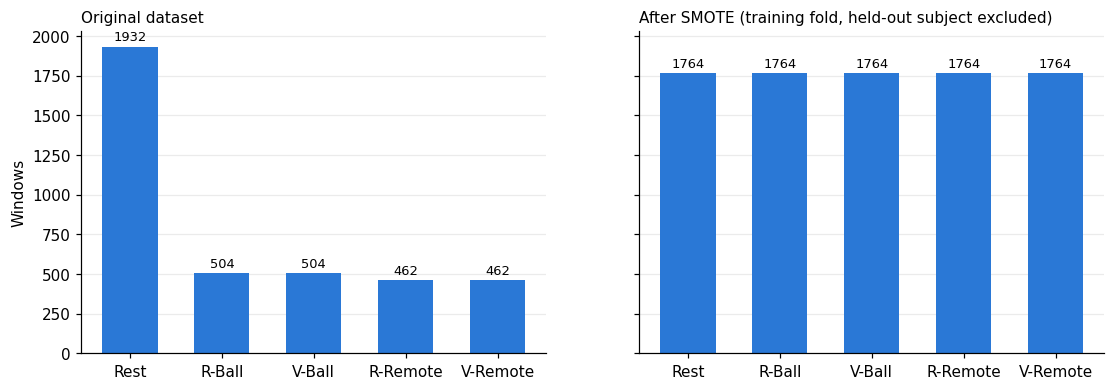

In [17]:
tr0 = SPLITS["LOSO"][0][0]
_, y_sm = SMOTE(random_state=SEED).fit_resample(StandardScaler().fit_transform(F_paper[tr0]), y[tr0])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cnt, t in zip(axs, [np.bincount(y, minlength=5), np.bincount(y_sm, minlength=5)],
                      ["Original dataset", "After SMOTE (training fold, held-out subject excluded)"]):
    b = ax.bar(SHORT, cnt, color=PAL[0], width=.6); ax.bar_label(b, padding=2, fontsize=8.5)
    ax.set_title(t, loc="left", fontsize=10); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("Windows"); savefig("fig03_class_distribution_smote")

### Fig 4 – CNN learning curves

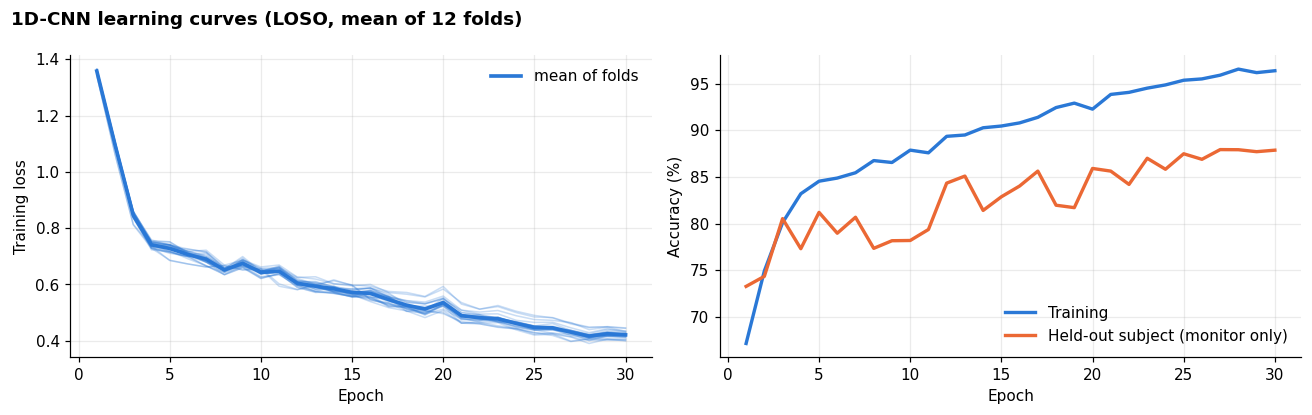

In [18]:
key = ("Novel: 1D-CNN-SE", "LOSO")
if key in MODELS_INFO:
    H = MODELS_INFO[key]; ep = np.arange(1, len(H[0]["loss"]) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    for h in H: axs[0].plot(ep, h["loss"], color=PAL[0], alpha=.25, lw=1)
    axs[0].plot(ep, np.mean([h["loss"] for h in H], 0), color=PAL[0], lw=2.4, label="mean of folds")
    axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Training loss"); axs[0].legend(frameon=False)
    axs[1].plot(ep, np.mean([h["train_acc"] for h in H], 0)*100, color=PAL[0], lw=2.2, label="Training")
    axs[1].plot(ep, np.mean([h["heldout_acc"] for h in H], 0)*100, color=PAL[1], lw=2.2, label="Held-out subject (monitor only)")
    axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Accuracy (%)"); axs[1].legend(frameon=False, loc="lower right")
    fig.suptitle("1D-CNN learning curves (LOSO, mean of 12 folds)", x=.01, ha="left", fontweight="bold")
    plt.tight_layout(); savefig("fig04_cnn_learning_curves")

### Fig 5 – Model comparison (macro-F1 and accuracy, LOSO vs 20-fold)

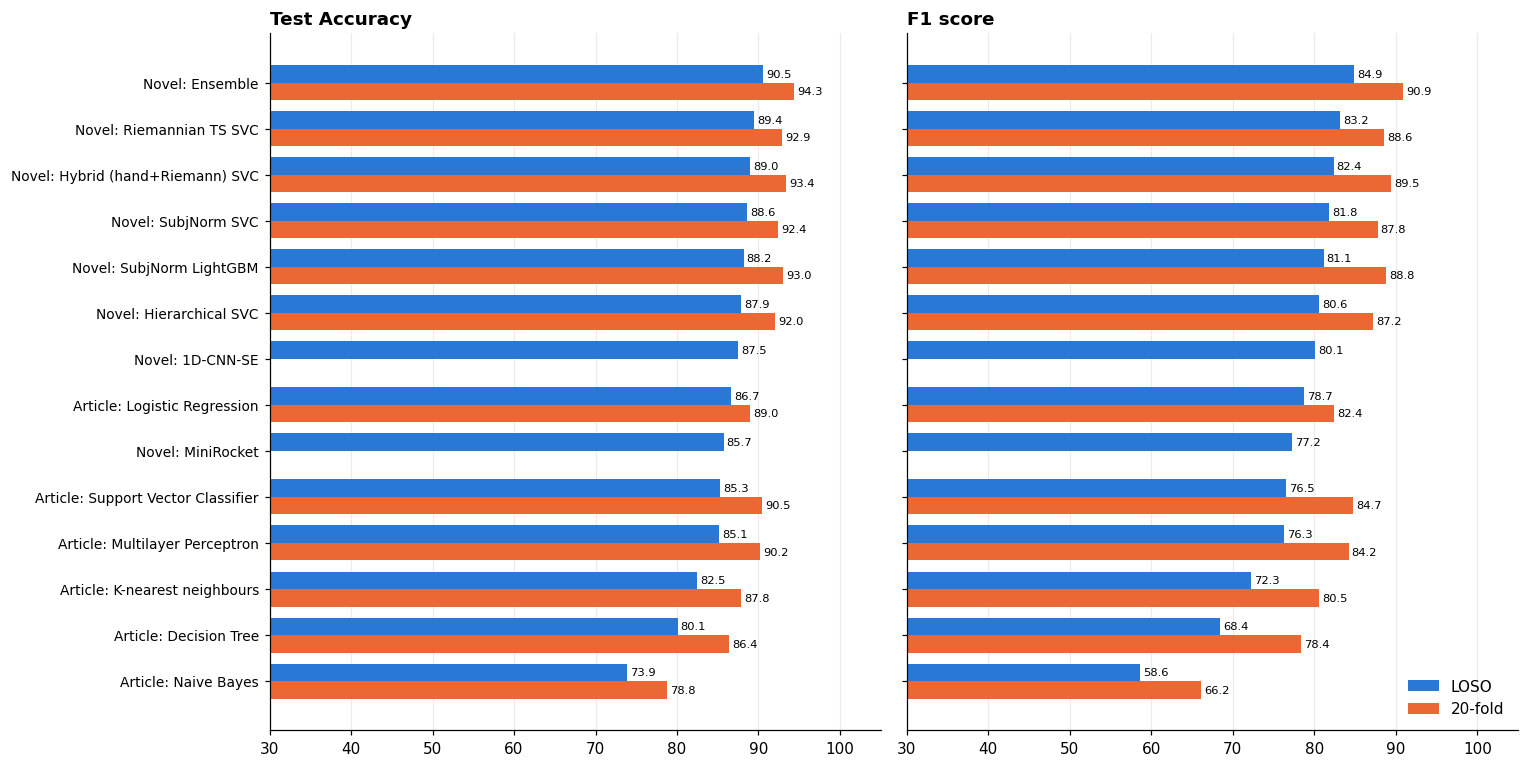

In [19]:
order = TABLES["LOSO"].sort_values("F1 score").Model.tolist()
fig, axs = plt.subplots(1, 2, figsize=(14, 0.42*len(order) + 1.2), sharey=True)
for ax, metric in zip(axs, ["Test Accuracy", "F1 score"]):
    yy = np.arange(len(order)); h = .38
    for i, cv in enumerate(CV_SCHEMES):
        t = TABLES[cv].set_index("Model").reindex(order)[metric]
        b = ax.barh(yy + (h/2 if i == 0 else -h/2), t.values, h, color=PAL[i], label=cv)
        ax.bar_label(b, fmt="%.1f", padding=2, fontsize=7.5)
    ax.set_yticks(yy, order, fontsize=9); ax.set_xlim(30, 105); ax.set_title(metric, loc="left", fontweight="bold")
    ax.grid(axis="y", visible=False)
axs[1].legend(frameon=False, loc="lower right"); plt.tight_layout(); savefig("fig05_model_comparison")

### Fig 6 – Train vs test accuracy (over-fitting check, LOSO)

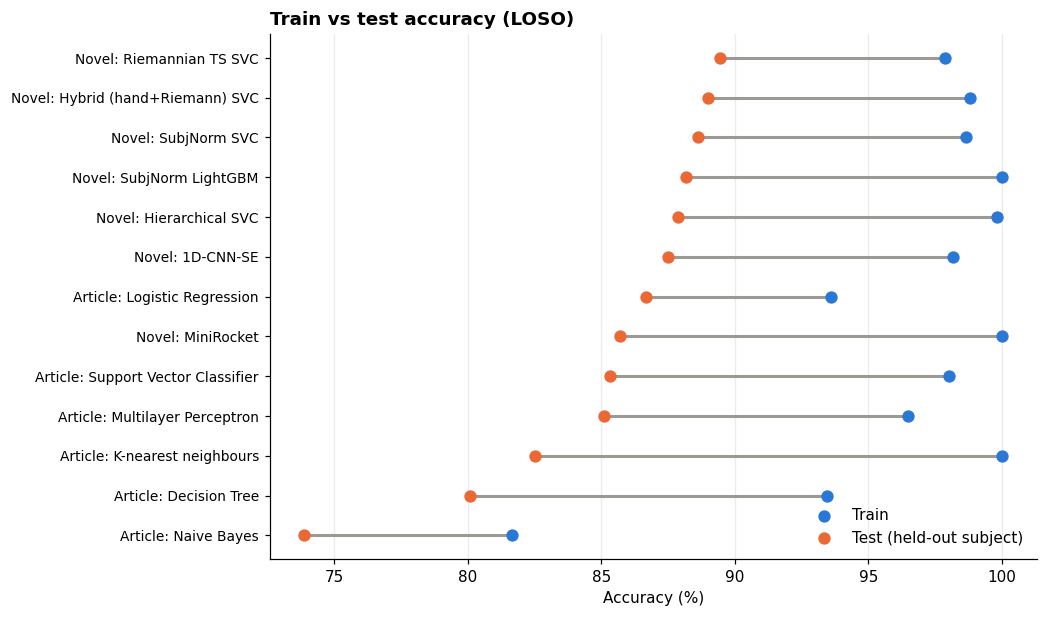

In [20]:
t = TABLES["LOSO"].dropna(subset=["Train Accuracy"]).sort_values("Test Accuracy")
fig, ax = plt.subplots(figsize=(9, 0.4*len(t) + 1)); yy = np.arange(len(t))
ax.hlines(yy, t["Test Accuracy"], t["Train Accuracy"], color=GREY, lw=2)
ax.scatter(t["Train Accuracy"], yy, color=PAL[0], s=50, zorder=3, label="Train")
ax.scatter(t["Test Accuracy"], yy, color=PAL[1], s=50, zorder=3, label="Test (held-out subject)")
ax.set_yticks(yy, t.Model, fontsize=9); ax.set_xlabel("Accuracy (%)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right"); ax.set_title("Train vs test accuracy (LOSO)", loc="left", fontweight="bold")
savefig("fig06_train_vs_test")

### Fig 7 – Confusion matrices: all article classifiers (LOSO)

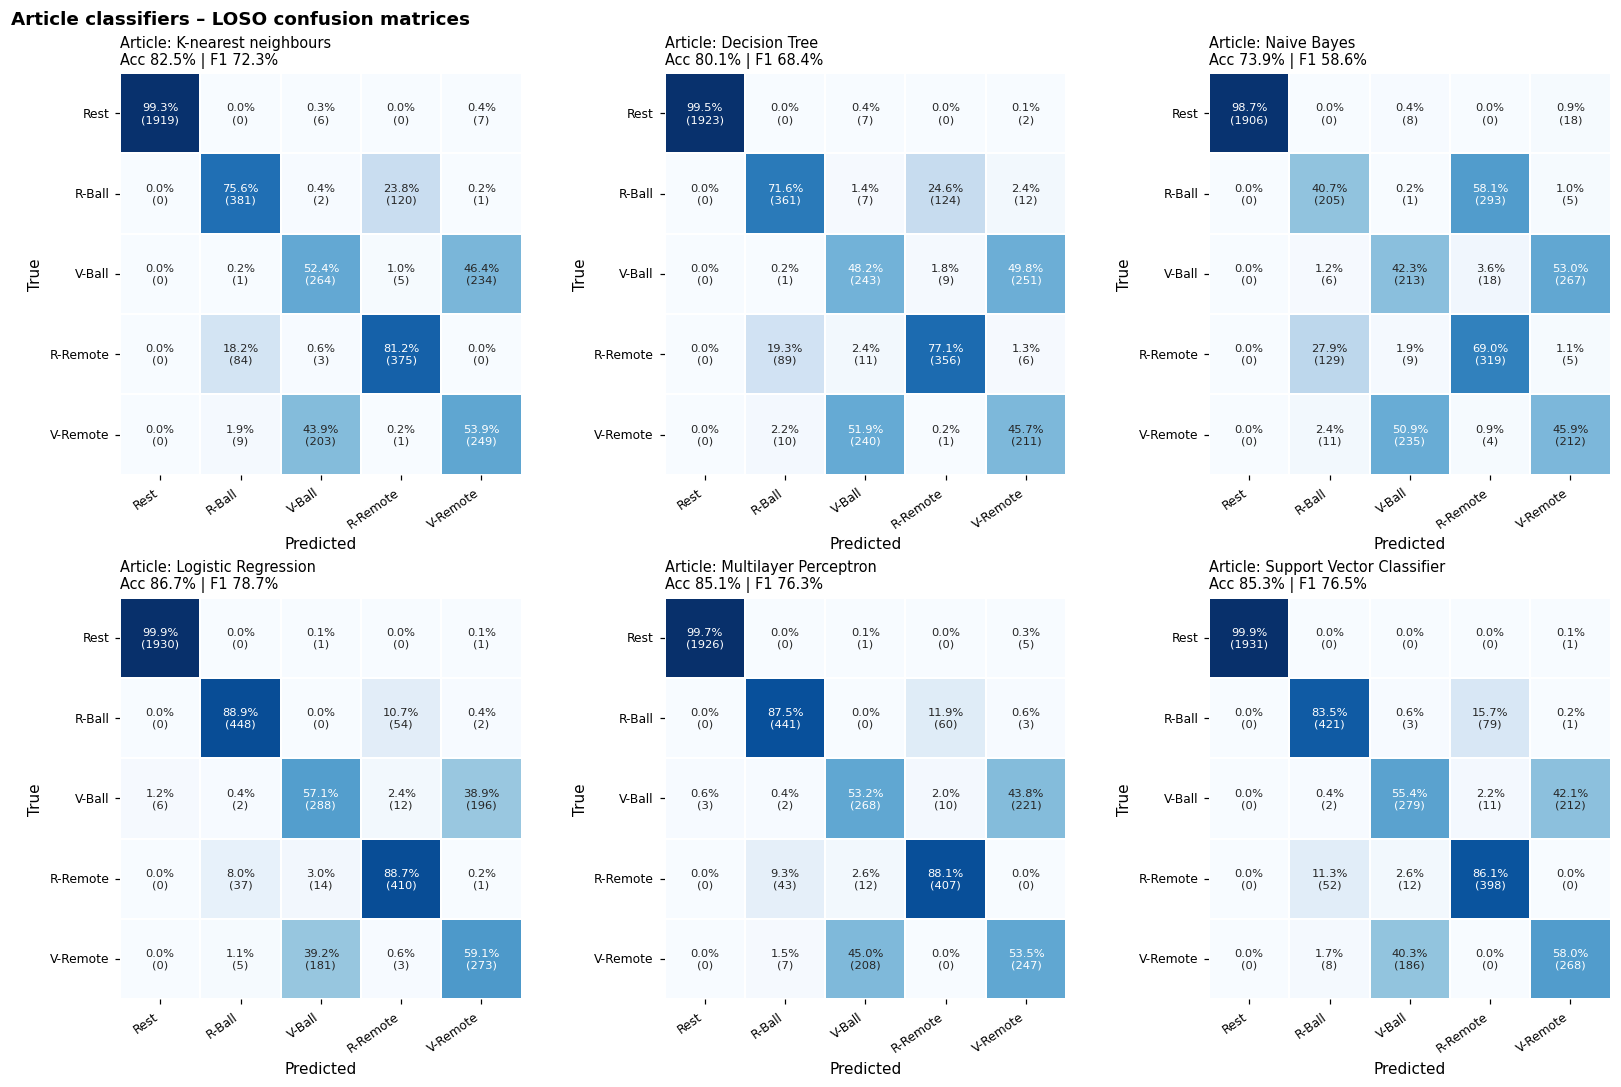

In [21]:
def plot_cm(ax, P, title, yt=None):
    yt = y if yt is None else yt
    cm = confusion_matrix(yt, P.argmax(1), labels=range(5)); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    sns.heatmap(cmn, ax=ax, cmap="Blues", vmin=0, vmax=100, cbar=False, square=True, linewidths=1, linecolor="white",
                annot=np.array([[f"{cmn[i,j]:.1f}%\n({cm[i,j]})" for j in range(5)] for i in range(5)]), fmt="", annot_kws={"fontsize": 7.5})
    ax.set_xticklabels(SHORT, rotation=35, ha="right", fontsize=8); ax.set_yticklabels(SHORT, rotation=0, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=9.5, loc="left")
def cm_grid(names, cv, fname, suptitle):
    names = [n for n in names if (n, cv) in PROBA]
    nr = int(np.ceil(len(names)/3)); fig, axs = plt.subplots(nr, 3, figsize=(15, 5*nr)); axs = np.atleast_1d(axs).ravel()
    for ax, n in zip(axs, names):
        r = [q for q in SUMMARY if q["Model"] == n and q["CV"] == cv][0]
        plot_cm(ax, PROBA[(n, cv)], f"{n}\nAcc {r['Test Accuracy']:.1f}% | F1 {r['F1 score']:.1f}%")
    for ax in axs[len(names):]: ax.axis("off")
    fig.suptitle(suptitle, x=.01, ha="left", fontweight="bold", fontsize=12); plt.tight_layout(); savefig(fname)
cm_grid([f"Article: {n}" for n in ARTICLE], "LOSO", "fig07_cm_article_LOSO", "Article classifiers – LOSO confusion matrices")

### Fig 8 – Confusion matrices: novel techniques (LOSO)

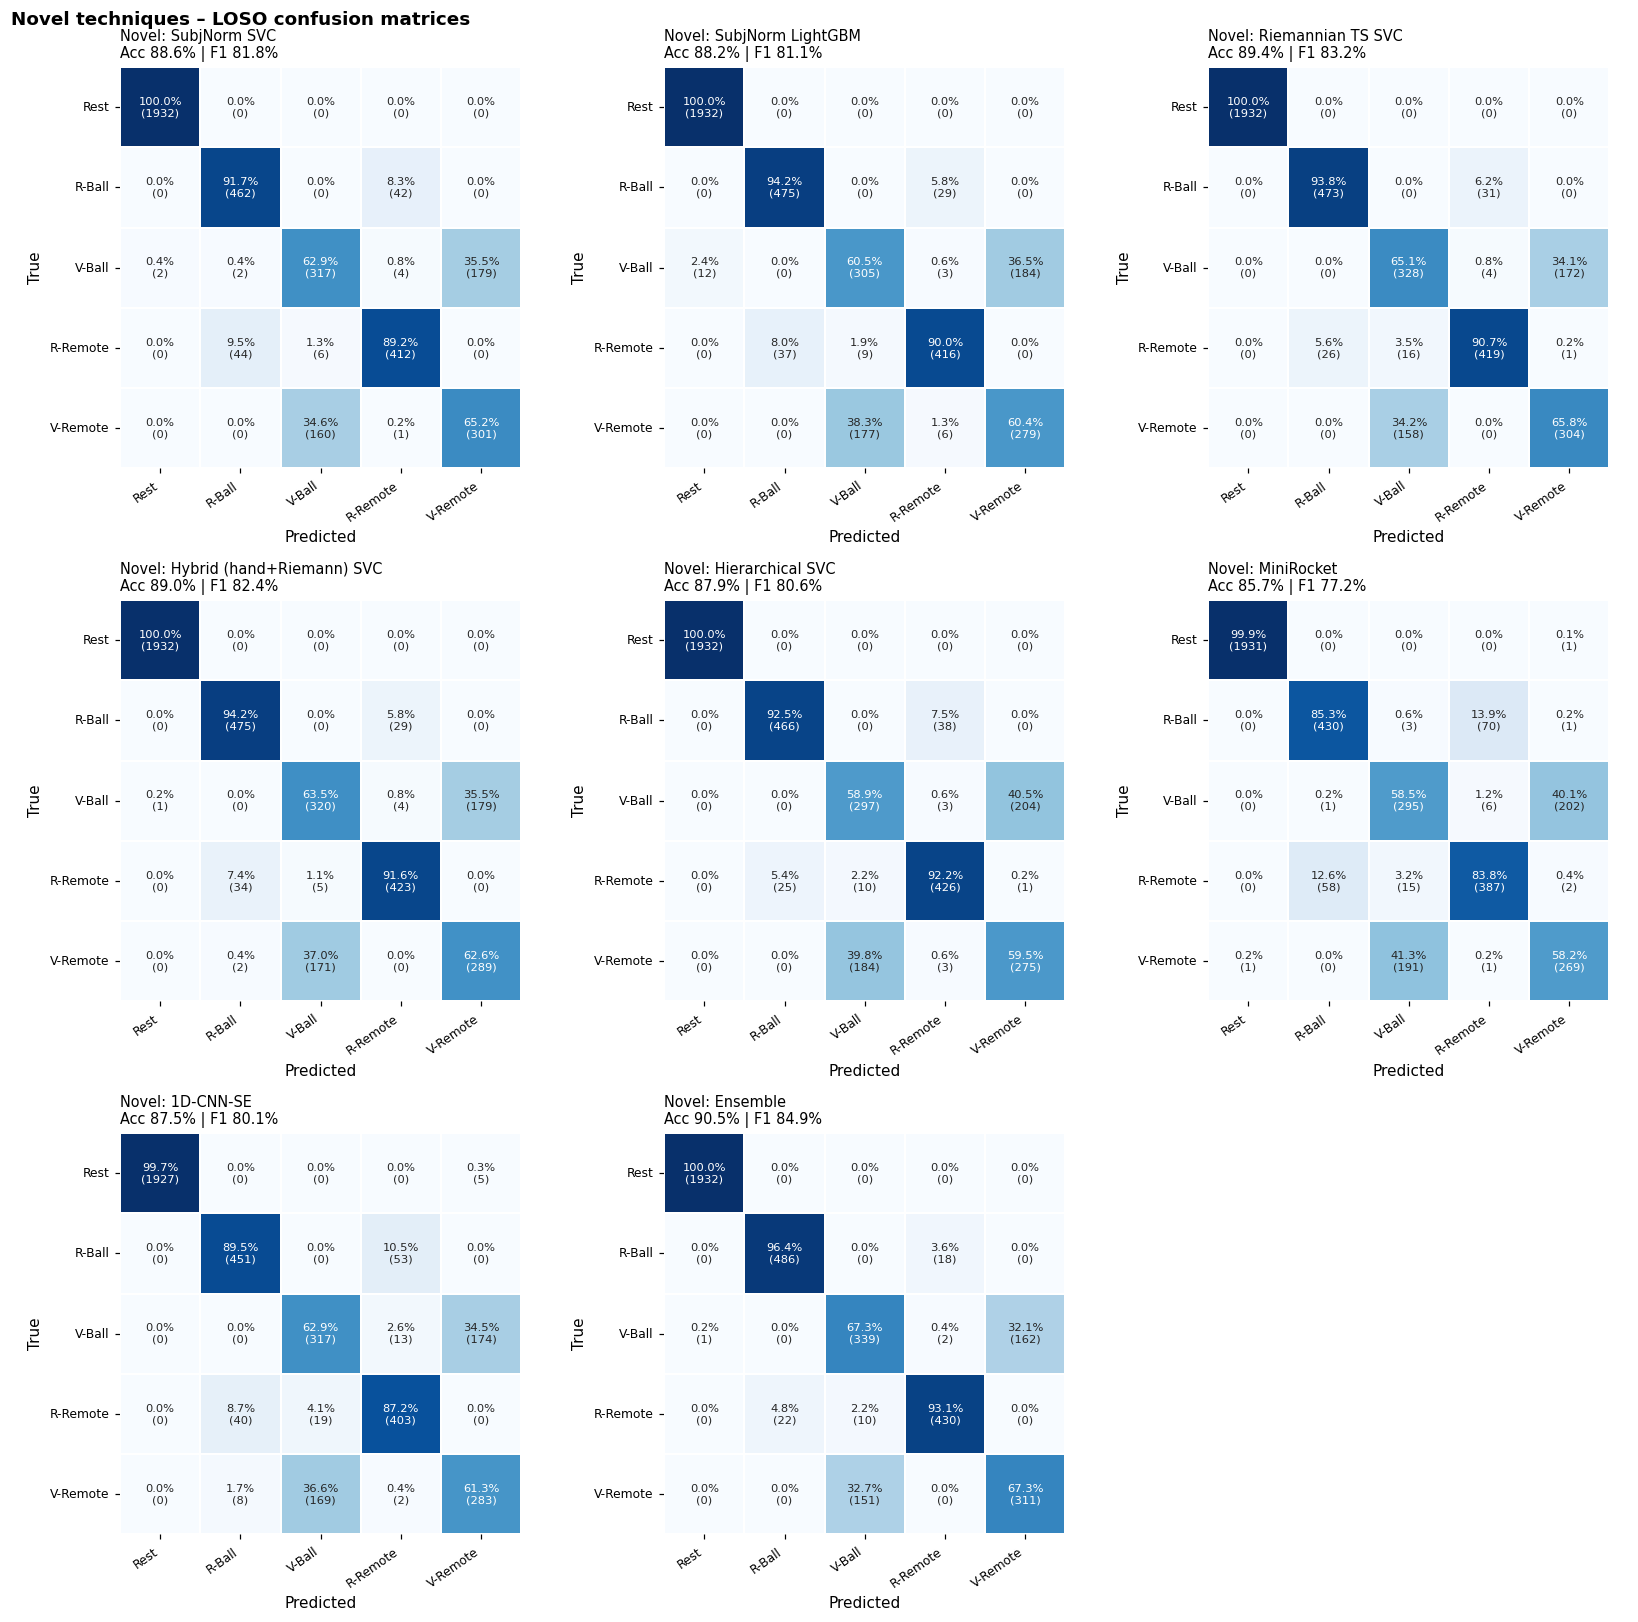

In [22]:
NOVEL = ["Novel: SubjNorm SVC", "Novel: SubjNorm LightGBM", "Novel: Riemannian TS SVC", "Novel: Hybrid (hand+Riemann) SVC",
         "Novel: Hierarchical SVC", "Novel: MiniRocket", "Novel: 1D-CNN-SE", "Novel: Ensemble"]
cm_grid(NOVEL, "LOSO", "fig08_cm_novel_LOSO", "Novel techniques – LOSO confusion matrices")

### Fig 9 – Confusion matrices under 20-fold CV

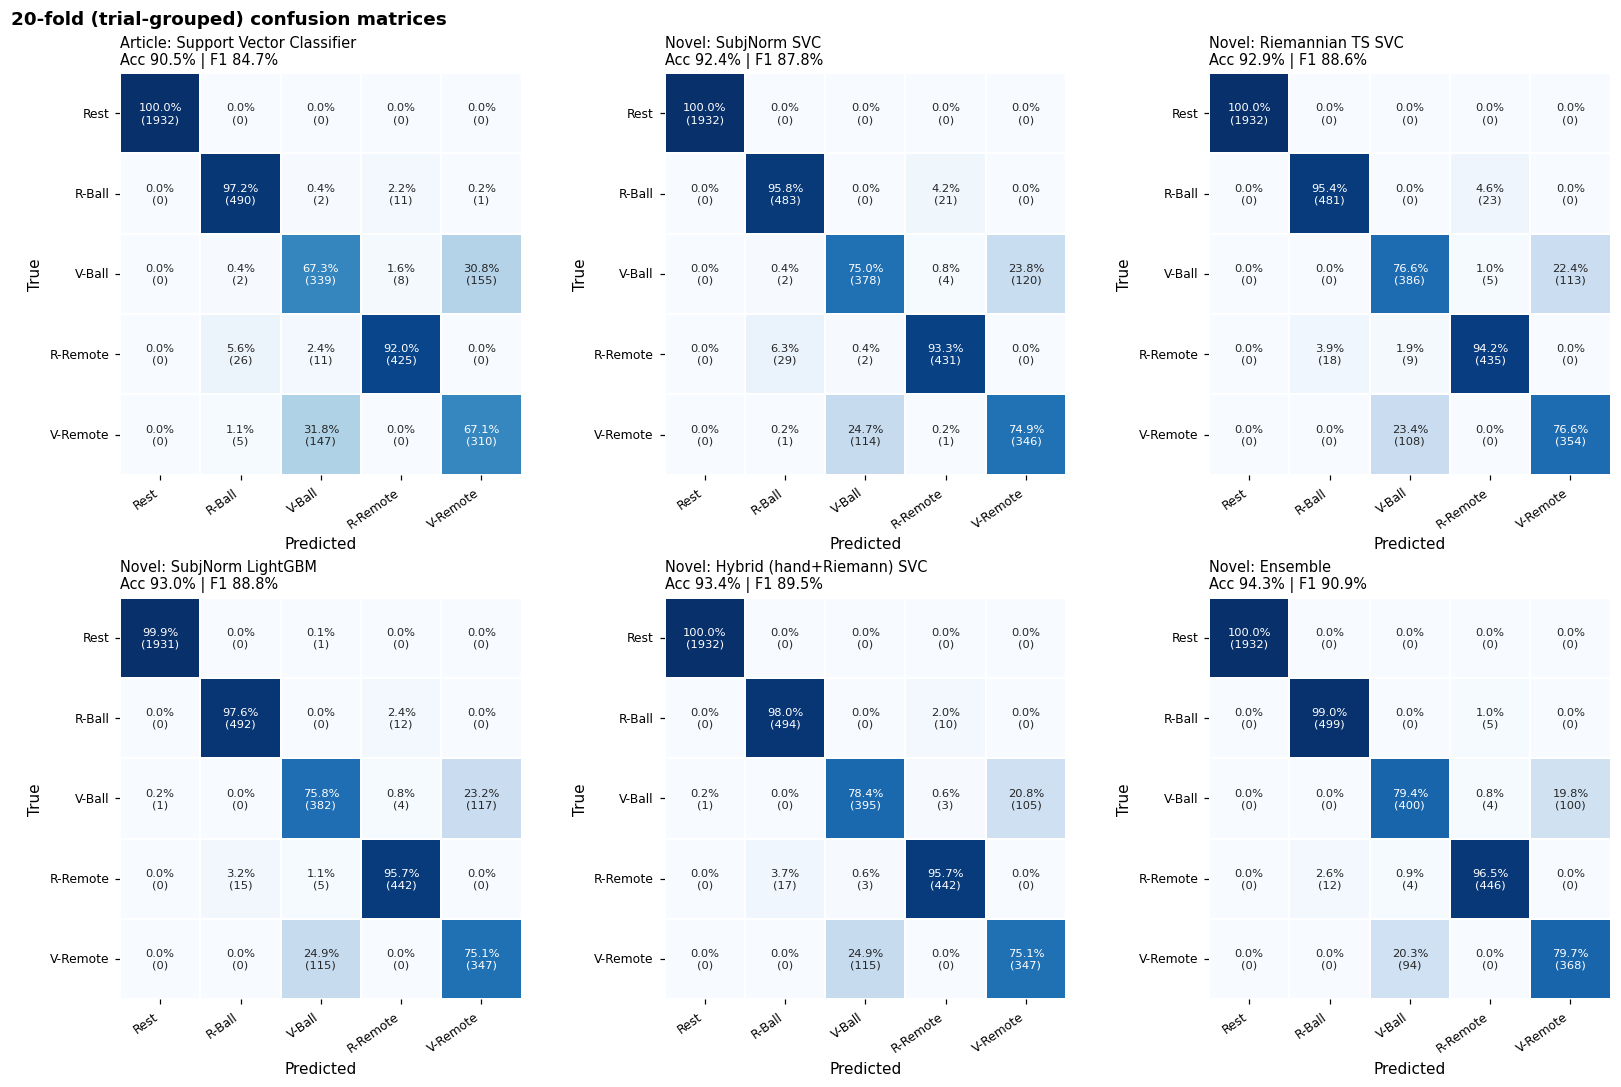

In [23]:
if "20-fold" in CV_SCHEMES:
    cm_grid(["Article: Support Vector Classifier", "Novel: SubjNorm SVC", "Novel: Riemannian TS SVC",
             "Novel: SubjNorm LightGBM", "Novel: Hybrid (hand+Riemann) SVC", "Novel: Ensemble"],
            "20-fold", "fig09_cm_20fold", "20-fold (trial-grouped) confusion matrices")

### Fig 10 – Best model: window-level and trial-level confusion matrix + classification report

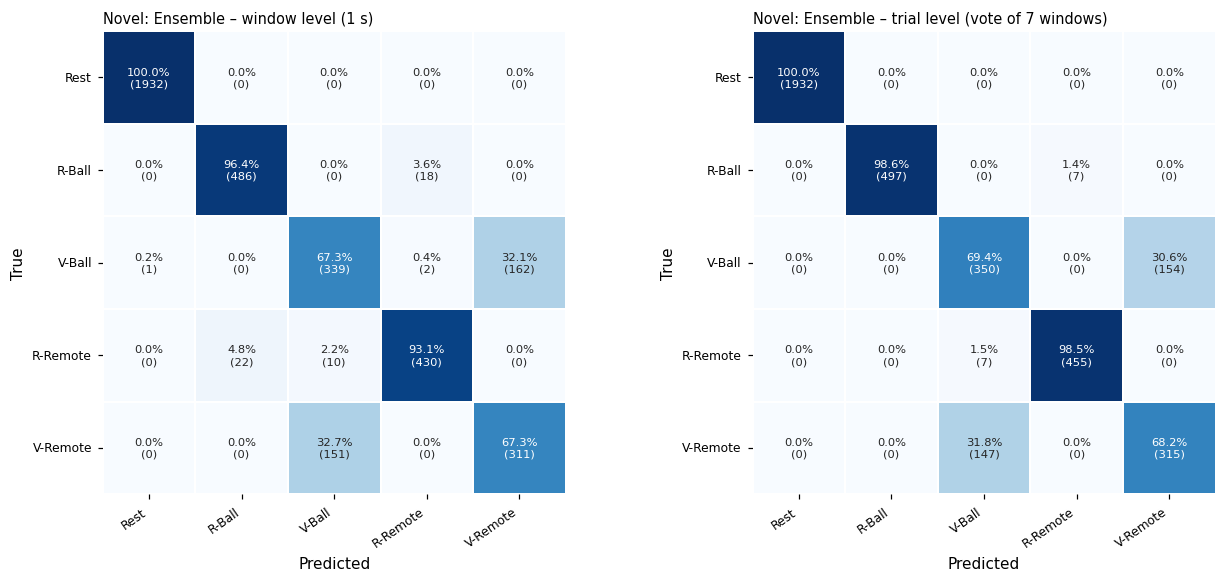

                precision    recall  f1-score   support

          Rest     0.9995    1.0000    0.9997      1932
     Real Ball     0.9567    0.9643    0.9605       504
  Virtual Ball     0.6780    0.6726    0.6753       504
   Real Remote     0.9556    0.9307    0.9430       462
Virtual Remote     0.6575    0.6732    0.6652       462

      accuracy                         0.9053      3864
     macro avg     0.8494    0.8482    0.8487      3864
  weighted avg     0.9058    0.9053    0.9055      3864



In [24]:
best = TABLES["LOSO"].iloc[0].Model; Pb = PROBA[(best, "LOSO")]
Pt = np.zeros_like(Pb)
for tt in np.unique(trial): m = trial == tt; Pt[m] = Pb[m].mean(0)
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
plot_cm(axs[0], Pb, f"{best} – window level (1 s)"); plot_cm(axs[1], Pt, f"{best} – trial level (vote of 7 windows)")
plt.tight_layout(); savefig("fig10_cm_best_model")
print(classification_report(y, Pb.argmax(1), target_names=CLASS_NAMES, digits=4))

### Fig 11 – Per-fold accuracy curves (LOSO subjects and 20 folds)

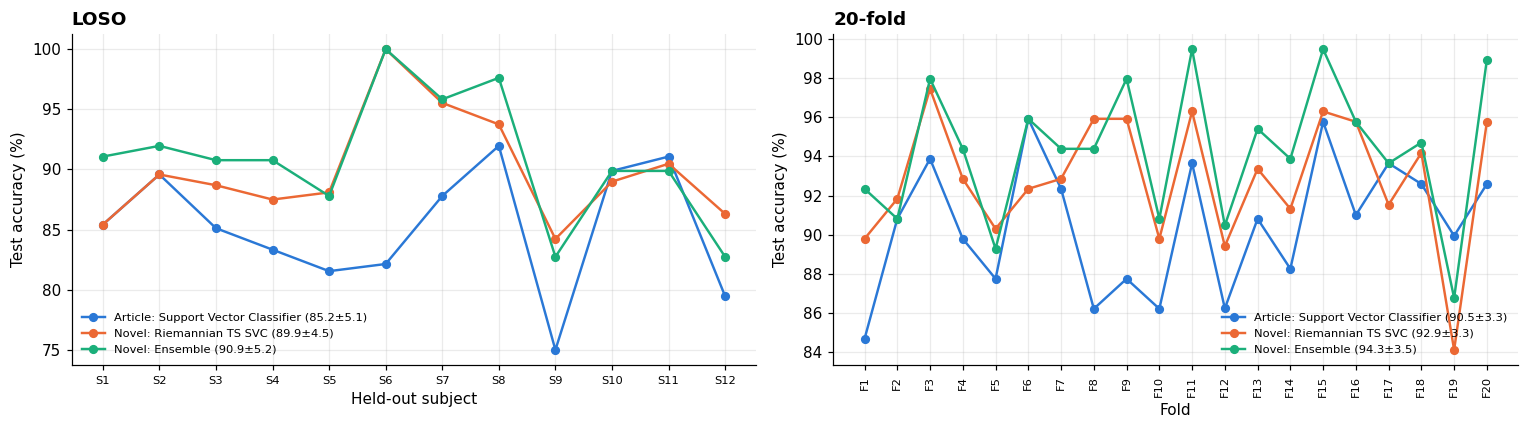

In [25]:
curve_models = ["Article: Support Vector Classifier", "Novel: Riemannian TS SVC", "Novel: Ensemble"]
fig, axs = plt.subplots(1, len(CV_SCHEMES), figsize=(7*len(CV_SCHEMES), 4), squeeze=False); axs = axs[0]
for ax, cv in zip(axs, CV_SCHEMES):
    for i, m in enumerate(curve_models):
        if (m, cv) not in FOLDS: continue
        fd = FOLDS[(m, cv)]
        ax.plot(range(1, len(fd)+1), fd.test_acc*100, "-o", ms=5, lw=1.6, color=PAL[i], label=f"{m} ({fd.test_acc.mean()*100:.1f}±{fd.test_acc.std()*100:.1f})")
    ax.set_xticks(range(1, len(fd)+1), fd.fold, fontsize=7.5, rotation=0 if cv == "LOSO" else 90)
    ax.set_xlabel("Held-out subject" if cv == "LOSO" else "Fold"); ax.set_ylabel("Test accuracy (%)")
    ax.set_title(cv, loc="left", fontweight="bold"); ax.legend(frameon=False, fontsize=7.5, loc="best")
plt.tight_layout(); savefig("fig11_per_fold_accuracy")

### Fig 12 – Per-class F1 and Wilcoxon signed-rank test

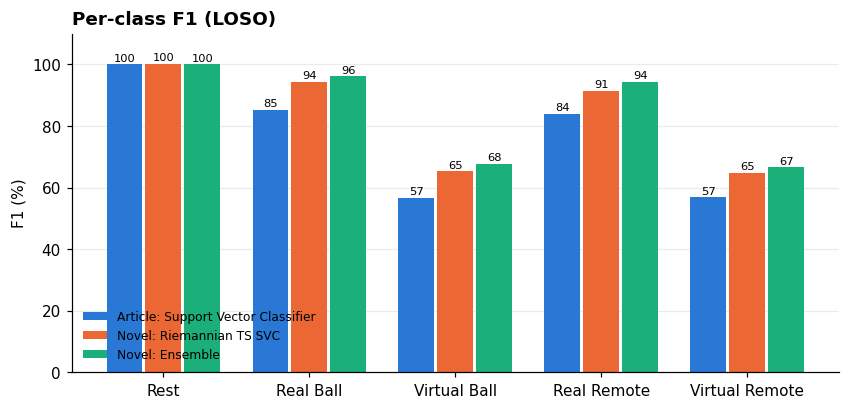

,Model,Metric,Article_SVC,Model_mean,Improved,W,p_value,rank_biserial
0,Novel: Ensemble,acc,85.1935,90.9226,10/12,1.0,0.0020,0.9744
1,Novel: Ensemble,f1,73.8174,85.0846,11/12,2.0,0.0015,0.9487
2,Novel: Riemannian TS SVC,acc,85.1935,89.8810,8/12,3.0,0.0098,0.9231
3,Novel: Riemannian TS SVC,f1,73.8174,83.5983,10/12,7.0,0.0093,0.8205
4,Novel: Hybrid (hand+Riemann) SVC,acc,85.1935,89.4097,11/12,3.5,0.0029,0.9103
5,Novel: Hybrid (hand+Riemann) SVC,f1,73.8174,79.5205,11/12,4.0,0.0034,0.8974
6,Novel: SubjNorm SVC,acc,85.1935,88.9137,10/12,3.0,0.0024,0.9231
7,Novel: SubjNorm SVC,f1,73.8174,78.9725,11/12,2.0,0.0015,0.9487
8,Novel: SubjNorm LightGBM,acc,85.1935,88.5417,9/12,15.0,0.0620,0.6154
9,Novel: SubjNorm LightGBM,f1,73.8174,78.3021,9/12,14.0,0.0522,0.6410


In [26]:
cmp = [m for m in ["Article: Support Vector Classifier", "Novel: Riemannian TS SVC", "Novel: Ensemble"] if (m, "LOSO") in PROBA]
pf = np.array([f1_score(y, PROBA[(m, "LOSO")].argmax(1), average=None)*100 for m in cmp])
fig, ax = plt.subplots(figsize=(9, 4)); w = .8/len(cmp); xx = np.arange(5)
for i, m in enumerate(cmp):
    b = ax.bar(xx + (i - (len(cmp)-1)/2)*w, pf[i], w*.92, color=PAL[i], label=m); ax.bar_label(b, fmt="%.0f", fontsize=7.5, padding=1)
ax.set_xticks(xx, CLASS_NAMES); ax.set_ylabel("F1 (%)"); ax.set_ylim(0, 110); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower left"); ax.set_title("Per-class F1 (LOSO)", loc="left", fontweight="bold"); savefig("fig12_per_class_f1")

def per_subject(P, metric):
    pr = P.argmax(1)
    return np.array([(accuracy_score(y[subj==u], pr[subj==u]) if metric == "acc" else f1_score(y[subj==u], pr[subj==u], average="macro")) for u in SUBJ])*100
rows = []
base = "Article: Support Vector Classifier"
for m in [q for q in TABLES["LOSO"].Model if q != base]:
    for metric in ["acc", "f1"]:
        a, b = per_subject(PROBA[(base, "LOSO")], metric), per_subject(PROBA[(m, "LOSO")], metric)
        if np.allclose(a, b): continue
        st = wilcoxon(b, a); n = len(a); rbc = 1 - 2*min(st.statistic, n*(n+1)/2 - st.statistic)/(n*(n+1)/2)
        rows.append(dict(Model=m, Metric=metric, Article_SVC=a.mean(), Model_mean=b.mean(), Improved=f"{(b>a).sum()}/{n}",
                         W=st.statistic, p_value=st.pvalue, rank_biserial=rbc))
wil = pd.DataFrame(rows).round(4); wil.to_csv(os.path.join(OUT_DIR, "wilcoxon_vs_article_SVC.csv"), index=False); display(wil)

### Fig 13 – Single vs fused muscles

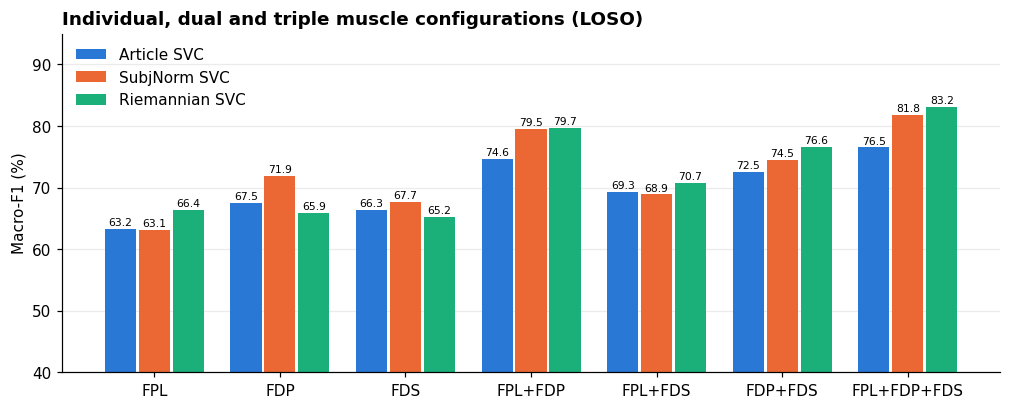

In [27]:
if RUN_MUSCLE_ANALYSIS:
    pv = muscle_df.pivot(index="Configuration", columns="Method", values="F1 score").loc[list(CONFIGS)]
    fig, ax = plt.subplots(figsize=(11, 4)); w = .27; xx = np.arange(len(pv))
    for i, m in enumerate(["Article SVC", "SubjNorm SVC", "Riemannian SVC"]):
        b = ax.bar(xx + (i-1)*w, pv[m], w*.92, color=PAL[i], label=m); ax.bar_label(b, fmt="%.1f", fontsize=7, padding=1)
    ax.set_xticks(xx, pv.index); ax.set_ylabel("Macro-F1 (%)"); ax.set_ylim(40, 95); ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, loc="upper left"); ax.set_title("Individual, dual and triple muscle configurations (LOSO)", loc="left", fontweight="bold")
    savefig("fig13_muscle_configurations")

### Fig 14 – ROC curves (best model) · Fig 15 – t-SNE · Fig 16 – feature importance

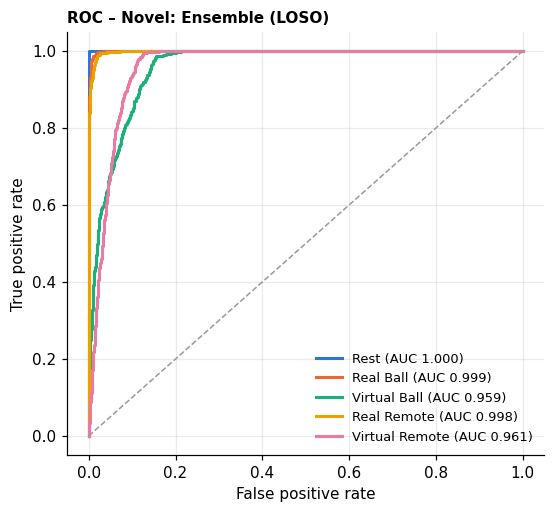

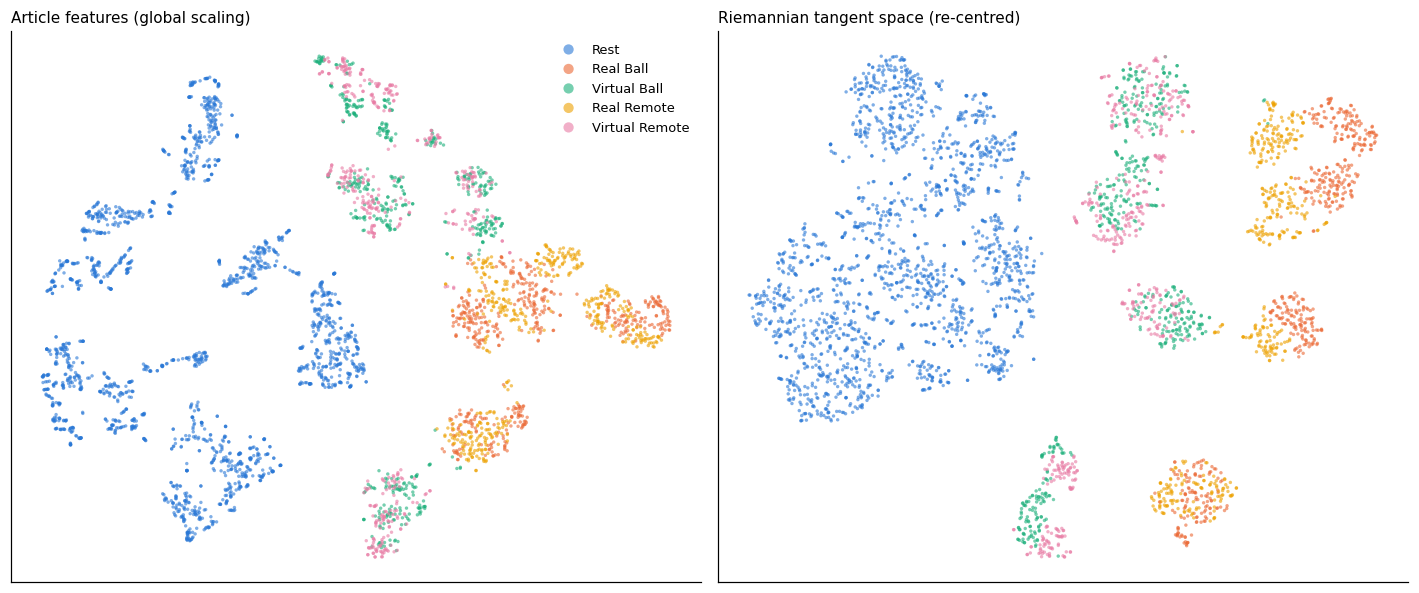

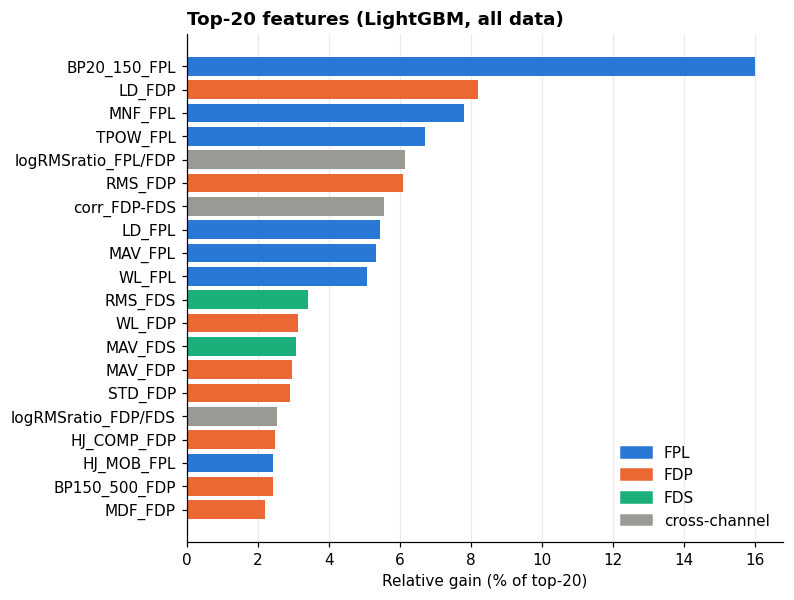

In [28]:
Yb = label_binarize(y, classes=range(5))
fig, ax = plt.subplots(figsize=(5.6, 5))
for k in range(5):
    fpr, tpr, _ = roc_curve(Yb[:, k], Pb[:, k]); ax.plot(fpr, tpr, color=PAL[k], lw=2, label=f"{CLASS_NAMES[k]} (AUC {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); ax.set_title(f"ROC – {best} (LOSO)", loc="left", fontweight="bold", fontsize=10)
savefig("fig14_roc")

from sklearn.manifold import TSNE
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (M, t) in zip(axs, [(StandardScaler().fit_transform(F_paper), "Article features (global scaling)"),
                            (StandardScaler().fit_transform(F_riem), "Riemannian tangent space (re-centred)")]):
    Z = TSNE(2, perplexity=40, random_state=SEED, init="pca").fit_transform(M)
    for k in range(5): m = y == k; ax.scatter(Z[m, 0], Z[m, 1], s=5, color=PAL[k], alpha=.6, label=CLASS_NAMES[k], edgecolors="none")
    ax.set_title(t, loc="left", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axs[0].legend(markerscale=3, frameon=False, fontsize=8.5); plt.tight_layout(); savefig("fig15_tsne")

m_imp = lgbm().set_params(importance_type="gain").fit(F_allN, y)
imp = pd.Series(m_imp.feature_importances_, index=N_all).sort_values().tail(20); imp = imp/imp.sum()*100
fig, ax = plt.subplots(figsize=(7, 6))
cols = [PAL[CH_NAMES.index(n.split("_")[-1])] if n.split("_")[-1] in CH_NAMES else GREY for n in imp.index]
ax.barh(imp.index, imp.values, color=cols); ax.set_xlabel("Relative gain (% of top-20)"); ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PAL[i], label=CH_NAMES[i]) for i in range(3)] + [Patch(color=GREY, label="cross-channel")], frameon=False, loc="lower right")
ax.set_title("Top-20 features (LightGBM, all data)", loc="left", fontweight="bold"); savefig("fig16_feature_importance")

## 10. Train final models on ALL data and save them

In [29]:
import joblib
FINAL = {"article_svc": (svc_smote(10), F_paper), "subjnorm_svc": (svc_smote(10), F_hand),
         "subjnorm_lightgbm": (lgbm, F_allN), "riemannian_svc": (svc_bal(10), F_riem)}
for nm, (b, Xf) in FINAL.items():
    t0 = time.time(); mdl = b().fit(Xf, y); joblib.dump(mdl, os.path.join(MODEL_DIR, f"{nm}.joblib"))
    print(f"saved {nm}.joblib  ({time.time()-t0:.1f}s)")
if RUN_CNN:
    CURRENT["monitor"] = (None, None); cnn_final = CNNClassifier().fit(Xn, y)
    torch.save(cnn_final.net.state_dict(), os.path.join(MODEL_DIR, "cnn_se.pt")); print("saved cnn_se.pt")
json.dump({"classes": CLASS_NAMES, "channels": CH_NAMES, "fs": FS, "window_s": 1.0, "step_s": 0.5,
           "bandpass": [20, 450], "notch": 50, "riemann_bands": BANDS,
           "note": "subject-normalised / Riemannian models need the new subject's unlabelled windows for normalisation"},
          open(os.path.join(MODEL_DIR, "preprocessing.json"), "w"), indent=1)

saved article_svc.joblib  (2.7s)
saved subjnorm_svc.joblib  (2.2s)
saved subjnorm_lightgbm.joblib  (1.9s)
saved riemannian_svc.joblib  (0.3s)
saved cnn_se.pt


### Inference example — load a saved model and predict

In [30]:
mdl = joblib.load(os.path.join(MODEL_DIR, "riemannian_svc.joblib"))
u = SUBJ[0]; m = subj == u
pred = mdl.predict_proba(F_riem[m]).argmax(1)
print(f"Subject {u}: predicted class counts", dict(zip(CLASS_NAMES, np.bincount(pred, minlength=5).tolist())))
print("(model was trained on all subjects incl. this one - this only demonstrates loading/predicting; use LOSO numbers for reporting)")
print("\nAll outputs written to:", os.path.abspath(OUT_DIR)); print(sorted(os.listdir(FIG_DIR)))

Subject 1: predicted class counts {'Rest': 168, 'Real Ball': 42, 'Virtual Ball': 45, 'Real Remote': 42, 'Virtual Remote': 39}
(model was trained on all subjects incl. this one - this only demonstrates loading/predicting; use LOSO numbers for reporting)

All outputs written to: /home/fawadsalamkhan/Downloads/outputs
['fig01_signals.png', 'fig02_rms_box.png', 'fig03_class_distribution_smote.png', 'fig04_cnn_learning_curves.png', 'fig05_model_comparison.png', 'fig06_train_vs_test.png', 'fig07_cm_article_LOSO.png', 'fig08_cm_novel_LOSO.png', 'fig09_cm_20fold.png', 'fig10_cm_best_model.png', 'fig11_per_fold_accuracy.png', 'fig12_per_class_f1.png', 'fig13_muscle_configurations.png', 'fig14_roc.png', 'fig15_tsne.png', 'fig16_feature_importance.png']
